In [37]:
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import random
from datetime import datetime, timedelta
from dateutil.relativedelta import relativedelta
import pprint
import pyspark
import pyspark.sql.functions as F
import utils
from pyspark.sql.functions import col
from pyspark.sql.types import StringType, IntegerType, FloatType, DateType

import utils.data_processing_bronze_table
import utils.data_processing_attribute_silver_table
import utils.data_processing_financials_silver_table
import utils.data_processing_clickstream_silver_table
import utils.data_processing_lms_silver_table
import utils.data_processing_lms_gold_table

pd.set_option("display.max_columns", None)


# For Machine Learning
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (roc_auc_score, roc_curve, average_precision_score, brier_score_loss,
                             log_loss, precision_score, recall_score, f1_score)
from sklearn.calibration import calibration_curve

import pickle, pprint


In [2]:
# ! pip install xgboost
from xgboost import XGBClassifier
import xgboost as xgb
import sklearn, joblib, json

RANDOM_STATE = 42
MODEL_DIR = "model_bank/"
print("sklearn", sklearn.__version__, "| xgboost", xgb.__version__)

sklearn 1.6.1 | xgboost 3.4.1


In [3]:
# Initialize SparkSession
spark = (
    pyspark.sql.SparkSession.builder
.appName("dev")
.master("local[*]")
.getOrCreate()
)

# Set log level to ERROR to hide warnings
spark.sparkContext.setLogLevel("ERROR")

# star is to use all available resources on the local machine. You can also specify a number, e.g., "local[4]" to use 4 cores.

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/20 14:46:13 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [4]:
gold_label_store_directory = "datamart/gold/label_store/"

if not os.path.exists(gold_label_store_directory):
    os.makedirs(gold_label_store_directory)

In [4]:
gold_label_store_directory = "datamart/gold/label_store/"
silver_loan_daily_directory = "datamart/silver/lms_loan_daily/"
# gold_label_main = utils.data_processing_lms_gold_table.process_labels_gold_table_main(silver_loan_daily_directory,gold_label_store_directory,spark,dpd = 30, mob = 6)

In [39]:
## setting up file directory config:
bronze_directory = "datamart/bronze/"

attribute_filename = "features_attributes/features_attributes_main.csv"
financial_filename = "features_financials/features_financials_main.csv"
loan_filename = "lms_loan_daily/lms_loan_daily_main.csv"
clickstream_filename = "feature_clickstream/feature_clickstream_main.csv"

silver_attributes_daily_directory = "datamart/silver/features_attributes/"
silver_financials_daily_directory = "datamart/silver/features_financials/"
silver_loan_daily_directory = "datamart/silver/lms_loan_daily/"
silver_clickstream_directory ="datamart/silver/feature_clickstream/"

silver_attribute_filename = "features_attributes/silver_features_attributes_main.parquet"
silver_financial_filename = "features_financials/silver_features_financials_main.parquet"
gold_loan_filename = "datamart/gold/label_store/gold_label_store_main_.parquet"
silver_clickstream_filename = "feature_clickstream/silver_clickstream_main_.parquet"


silver_directory = "datamart/silver/"
os.makedirs(silver_directory, exist_ok = True)

gold_directory = "datamart/gold/"
os.makedirs(gold_directory, exist_ok = True)

silver_merged_processed_directory = "datamart/silver/merged/"
os.makedirs(silver_merged_processed_directory, exist_ok = True)

gold_features_main_directory = "datamart/gold/feature_store/"
os.makedirs(gold_features_main_directory, exist_ok = True)


os.makedirs(bronze_directory, exist_ok = True)
os.makedirs(silver_attributes_daily_directory, exist_ok = True)
os.makedirs(silver_financials_daily_directory, exist_ok = True)
os.makedirs(silver_loan_daily_directory, exist_ok = True)
os.makedirs(silver_clickstream_directory, exist_ok = True)

data_start_date_str = "2023-01-01"
data_end_date_str = "2024-12-01"

train_end_date = '2024-09-01'
unseen_start_date = '2024-10-01'


In [4]:
utils.data_processing_lms_gold_table.process_features_gold_table_main(silver_directory, spark, 
                            silver_attribute_filename, silver_financial_filename, gold_loan_filename, silver_clickstream_filename,gold_features_main_directory,
                            train_end_date, unseen_start_date,data_start_date_str,data_end_date_str,
                            model_train_date_str="2025-06-01", validation_period_months=1,
                            test_period_months=2, oot_period_months=2)

loaded from: datamart/silver/features_attributes/silver_features_attributes_main.parquet row count: 12500
loaded from: datamart/silver/features_financials/silver_features_financials_main.parquet row count: 12500
loaded from: datamart/gold/label_store/gold_label_store_main_.parquet row count: 12500
loaded from: datamart/silver/feature_clickstream/silver_clickstream_main_.parquet row count: 215376

Date split boundaries:
Train: 2023-01-01 to 2024-12-31
Validation: 2025-01-01 to 2025-01-31
Test: 2025-02-01 to 2025-03-31
OOT: 2025-04-01 to 2025-05-31



Train: 8974 rows
+-----+-----+-------------------+
|label|count|         proportion|
+-----+-----+-------------------+
|    0| 6383| 0.7112770225094718|
|    1| 2591|0.28872297749052817|
+-----+-----+-------------------+

+----------+----------+
|  min_date|  max_date|
+----------+----------+
|2023-07-01|2024-12-01|
+----------+----------+


Validation: 505 rows
+-----+-----+------------------+
|label|count|        proportion|
+-----+-----+------------------+
|    0|  350| 0.693069306930693|
|    1|  155|0.3069306930693069|
+-----+-----+------------------+

+----------+----------+
|  min_date|  max_date|
+----------+----------+
|2025-01-01|2025-01-01|
+----------+----------+


Test: 1036 rows
+-----+-----+-------------------+
|label|count|         proportion|
+-----+-----+-------------------+
|    0|  710| 0.6853281853281853|
|    1|  326|0.31467181467181465|
+-----+-----+-------------------+

+----------+----------+
|  min_date|  max_date|
+----------+----------+
|2025-02-01|2025-03-

+------------+-------+------------------+----------+-----+
|  Occupation|Age_Bin| log_income_median|age_median|count|
+------------+-------+------------------+----------+-----+
|MediaManager|  35-42|10.482973805102581|        38|  134|
|  Accountant|  27-34|10.487246912994182|        30|  123|
|  Accountant|  18-26|10.534979551138033|        23|  124|
|     Teacher|  27-34|10.431097466232934|        31|  121|
|    Engineer|  27-34|10.547302713164944|        31|  133|
|   Scientist|  43-56|10.649030090887043|        47|  134|
|Entrepreneur|  18-26|10.461044078789724|        22|  128|
|            |  27-34|10.473715360069058|        31|  157|
|  Journalist|  35-42|10.353238088050679|        38|  128|
|MediaManager|  43-56|10.566129616052383|        48|  134|
|    Mechanic|  43-56|10.787507917792388|        48|  127|
|  Journalist|  27-34|10.521021256243461|        31|  121|
|      Doctor|  18-26|10.545569311592208|        22|  141|
|            |  18-26|10.518878618160022|        22|  13

+-----------+-----------------+-------------------+---------------------+-------------------------+-------------------------+-------------------------------+---------------+------------------+--------------------+------------------------+------------------------+------------------------------+
|Customer_ID|Num_Bank_Accounts|Bank_Accounts_clean|Bank_Accounts_imputed|Bank_Accounts_Imputed_Bin|Bank_Accounts_Was_Invalid|Bank_Accounts_imputation_method|Num_Credit_Card|Credit_Cards_clean|Credit_Cards_imputed|Credit_Cards_Imputed_Bin|Credit_Cards_Was_Invalid|Credit_Cards_imputation_method|
+-----------+-----------------+-------------------+---------------------+-------------------------+-------------------------+-------------------------------+---------------+------------------+--------------------+------------------------+------------------------+------------------------------+
|CUS_0x69cd |5                |5                  |5                    |4-5                      |0               

+-----------+-----------------+-------------------+---------------------+-------------------------+-------------------------+-------------------------------+---------------+------------------+--------------------+------------------------+------------------------+------------------------------+
|Customer_ID|Num_Bank_Accounts|Bank_Accounts_clean|Bank_Accounts_imputed|Bank_Accounts_Imputed_Bin|Bank_Accounts_Was_Invalid|Bank_Accounts_imputation_method|Num_Credit_Card|Credit_Cards_clean|Credit_Cards_imputed|Credit_Cards_Imputed_Bin|Credit_Cards_Was_Invalid|Credit_Cards_imputation_method|
+-----------+-----------------+-------------------+---------------------+-------------------------+-------------------------+-------------------------------+---------------+------------------+--------------------+------------------------+------------------------+------------------------------+
|CUS_0x559e |1665             |NULL               |6                    |6-7                      |1               

Length of temp after LEFT join: 215376


Length of filtered temp (days_before > 0): 129778


Feature rows after clickstream enrichment: 11459
Clickstream columns joined to gold table: ['labels_snapshot_date', 'fe_10_mean_90d', 'fe_5_mean_90d', 'fe_4_mean_90d', 'fe_9_mean_90d', 'fe_3_std_60d', 'fe_8_mean_90d', 'fe_3_mean_90d', 'fe_14_trend_30d', 'fe_1_trend_30d', 'fe_16_std_60d']


+-----------+--------------------+--------------------+--------------+-------------+------------------+------------------+------------+------------------+------------------+---------------+--------------+-------------+
|Customer_ID|labels_snapshot_date|labels_snapshot_date|fe_10_mean_90d|fe_5_mean_90d|fe_4_mean_90d     |fe_9_mean_90d     |fe_3_std_60d|fe_8_mean_90d     |fe_3_mean_90d     |fe_14_trend_30d|fe_1_trend_30d|fe_16_std_60d|
+-----------+--------------------+--------------------+--------------+-------------+------------------+------------------+------------+------------------+------------------+---------------+--------------+-------------+
|CUS_0x5035 |2024-06-01          |2024-06-01          |229.0         |42.0         |153.5             |130.0             |NULL        |121.0             |85.5              |NULL           |NULL          |NULL         |
|CUS_0x5036 |2023-10-01          |2023-10-01          |77.0          |131.5        |-62.5             |191.0             |NU

saved to: datamart/gold/feature_store/gold_feature_store_main_cs.parquet


In [6]:
fs_sdf_cs = spark.read.option("header", "true").parquet('datamart/gold/feature_store/gold_feature_store_main_cs.parquet')
fs_sdf_cs = fs_sdf_cs.toPandas()
display(fs_sdf_cs.head())
display(fs_sdf_cs.info())
print("number of customers:", fs_sdf_cs['Customer_ID'].nunique())

,Customer_ID,labels_snapshot_date,Occupation,Age_Bin,loan_id,Age,attributes_snapshot_date,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Outstanding_Debt,Credit_Utilization_Ratio,Total_EMI_per_month,Amount_invested_monthly,Monthly_Balance,financials_snapshot_date,Num_of_Loan_Cleaned,Loan_Home_Equity_Loan,Loan_Payday_Loan,Loan_Personal_Loan,Loan_Debt_Consolidation_Loan,Loan_Mortgage_Loan,Loan_Student_Loan,Loan_Credit_Builder_Loan,Loan_Auto_Loan,Loan_Not_Specified,Credit_Mix_Not_Defined,Credit_Mix_Good,Credit_Mix_Bad,Credit_Mix_Standard,Payment_of_Min_Amount_NM,Payment_of_Min_Amount_No,Payment_of_Min_Amount_Yes,Credit_History_Age_Years,Payment_Behaviour_Imputed,Age_imputed,Bank_Accounts_imputed,Credit_Cards_imputed,Bank_Accounts_Imputed_Bin,Credit_Cards_Imputed_Bin,Num_Fin_Pdts,Debt_per_Credit_Account,Delayed_Payments_per_Card,InterestRate_x_Debt,data_split,fe_10_mean_90d,fe_5_mean_90d,fe_4_mean_90d,fe_9_mean_90d,fe_3_std_60d,fe_8_mean_90d,fe_3_mean_90d,fe_14_trend_30d,fe_1_trend_30d,fe_16_std_60d
0,CUS_0x2174,2023-08-01,Manager,36-44,CUS_0x2174_2023_02_01,36,2023-02-01,94934.937500,8039.245117,2,5,3,11,11,6.83,0,975.210022,30.479555,289.841064,477.698914,306.384521,2023-02-01,4,1,0,0,0,0,1,0,1,0,0,1,0,0,0,1,0,23.333333,Low_spent_Large_value_payments,36,2,5,0-3,5-5,11,139.315717,2.200000,2925.630127,train,170.500000,66.0,-55.500000,3.000000,NaN,141.500000,188.5,NaN,NaN,NaN
1,CUS_0x78eb,2024-05-01,Musician,36-44,CUS_0x78eb_2023_11_01,38,2023-11-01,131121.750000,11211.812500,4,3,2,10,5,2.88,3,1027.150024,31.824947,95.699142,354.328552,951.153564,2023-11-01,1,0,0,0,1,0,0,0,0,0,0,1,0,0,1,0,0,18.833333,Low_spent_Medium_value_payments,38,4,3,4-5,0-4,8,146.735718,1.666667,2054.300049,train,176.666667,168.0,47.333333,112.333333,NaN,147.666667,162.0,NaN,NaN,NaN
2,CUS_0x8bcc,2023-11-01,,45-56,CUS_0x8bcc_2023_05_01,51,2023-05-01,123485.039062,10299.419922,4,4,6,14,9,8.17,5,1063.390015,27.339819,290.019989,426.268982,563.653015,2023-05-01,3,0,0,0,0,1,0,0,1,0,0,1,0,0,0,1,0,19.750000,High_spent_Medium_value_payments,51,4,4,4-5,0-4,11,132.923752,2.250000,6380.339844,train,106.500000,42.5,171.000000,121.000000,NaN,-32.000000,-73.5,NaN,NaN,NaN
3,CUS_0x6f40,2024-04-01,Musician,31-35,CUS_0x6f40_2023_10_01,31,2023-10-01,82995.820312,7092.318359,2,2,10,4,10,2.05,615,1424.109985,34.770618,87.418037,254.442719,617.371094,2023-10-01,2,1,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0,27.833333,High_spent_Small_value_payments,31,2,2,0-3,0-4,6,356.027496,5.000000,14241.099609,train,37.000000,8.5,4.000000,145.500000,12.727922,-9.500000,157.0,NaN,NaN,65.053824
4,CUS_0x19a7,2024-07-01,Musician,31-35,CUS_0x19a7_2024_01_01,34,2024-01-01,62348.460938,4942.705078,4,3,16,18,21,7.30,10,1940.489990,31.395056,350.455841,93.759018,300.055634,2024-01-01,7,1,1,0,0,1,1,1,0,1,0,0,0,1,0,0,1,8.000000,High_spent_Medium_value_payments,34,4,3,4-5,0-4,14,277.212856,7.000000,31047.839844,train,154.000000,140.0,120.000000,108.500000,NaN,255.000000,167.0,NaN,NaN,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11459 entries, 0 to 11458
Data columns (total 61 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Customer_ID                   11459 non-null  object 
 1   labels_snapshot_date          11459 non-null  object 
 2   Occupation                    11459 non-null  object 
 3   Age_Bin                       11459 non-null  object 
 4   loan_id                       11459 non-null  object 
 5   Age                           11459 non-null  int32  
 6   attributes_snapshot_date      11459 non-null  object 
 7   Annual_Income                 11459 non-null  float32
 8   Monthly_Inhand_Salary         11459 non-null  float32
 9   Num_Bank_Accounts             11459 non-null  int32  
 10  Num_Credit_Card               11459 non-null  int32  
 11  Interest_Rate                 11459 non-null  int32  
 12  Delay_from_due_date           11459 non-null  int32  
 13  N

None

number of customers: 11459


In [7]:
fs_labels = spark.read.option("header", "true").parquet("datamart/gold/label_store/gold_label_store_main_.parquet")
fs_labels = fs_labels.toPandas()

In [8]:
fs_sdf_cs["labels_snapshot_date"] = pd.to_datetime(fs_sdf_cs["labels_snapshot_date"])
fs_labels["snapshot_date"] = pd.to_datetime(fs_labels["snapshot_date"])

In [23]:
fs_labels.head()

,loan_id,Customer_ID,label,label_def,snapshot_date
0,CUS_0x5002_2023_04_01,CUS_0x5002,1,30dpd_6mob,2023-10-01
1,CUS_0x500d_2024_12_01,CUS_0x500d,1,30dpd_6mob,2025-06-01
2,CUS_0x5012_2023_11_01,CUS_0x5012,1,30dpd_6mob,2024-05-01
3,CUS_0x501c_2024_03_01,CUS_0x501c,1,30dpd_6mob,2024-09-01
4,CUS_0x501d_2024_02_01,CUS_0x501d,0,30dpd_6mob,2024-08-01


In [9]:
combined = fs_sdf_cs.merge(
 fs_labels[["loan_id", "snapshot_date", "label"]],
    left_on=["loan_id", "labels_snapshot_date"],
    right_on=["loan_id", "snapshot_date"],
    how="left",
    validate="one_to_one"
).drop(columns=["snapshot_date"])

combined.describe()

/usr/local/lib/python3.12/site-packages/pandas/core/nanops.py:1025: RuntimeWarning: overflow encountered in cast
  result = result.astype(dtype, copy=False)


,labels_snapshot_date,Age,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Outstanding_Debt,Credit_Utilization_Ratio,Total_EMI_per_month,Amount_invested_monthly,Monthly_Balance,Num_of_Loan_Cleaned,Loan_Home_Equity_Loan,Loan_Payday_Loan,Loan_Personal_Loan,Loan_Debt_Consolidation_Loan,Loan_Mortgage_Loan,Loan_Student_Loan,Loan_Credit_Builder_Loan,Loan_Auto_Loan,Loan_Not_Specified,Credit_Mix_Not_Defined,Credit_Mix_Good,Credit_Mix_Bad,Credit_Mix_Standard,Payment_of_Min_Amount_NM,Payment_of_Min_Amount_No,Payment_of_Min_Amount_Yes,Credit_History_Age_Years,Age_imputed,Bank_Accounts_imputed,Credit_Cards_imputed,Num_Fin_Pdts,Debt_per_Credit_Account,Delayed_Payments_per_Card,InterestRate_x_Debt,fe_10_mean_90d,fe_5_mean_90d,fe_4_mean_90d,fe_9_mean_90d,fe_3_std_60d,fe_8_mean_90d,fe_3_mean_90d,fe_14_trend_30d,fe_1_trend_30d,fe_16_std_60d,label
count,11459,11459.000000,1.145900e+04,11459.000000,11459.000000,11459.000000,11459.000000,11459.000000,11459.000000,11459.000000,11459.000000,11459.000000,11459.000000,11459.000000,11459.000000,1.145900e+04,11459.000000,11459.000000,11459.000000,11459.000000,11459.000000,11459.000000,11459.000000,11459.000000,11459.000000,11459.000000,11459.000000,11459.000000,11459.000000,11459.000000,11459.000000,11459.000000,11459.000000,11459.000000,11459.000000,11459.000000,11459.000000,11459.000000,11020.000000,11175.000000,1.145900e+04,8974.000000,8974.000000,8974.000000,8974.000000,941.000000,8974.000000,8974.000000,454.000000,454.000000,941.000000,11459.000000
mean,2024-05-30 12:57:44.595514112,104.867004,1.640294e+05,4184.039062,17.053757,23.667336,73.688978,21.111964,33.228467,10.423083,26.571341,1433.739624,32.333549,1482.961182,638.552429,-2.908922e+22,3.650493,0.313116,0.320185,0.312418,0.310236,0.315036,0.309102,0.318265,0.307095,0.429968,0.209355,0.242866,0.191029,0.356750,0.115630,0.357710,0.526660,18.682389,36.226809,5.366960,5.549001,44.371586,131.680365,7.140098,1.095225e+05,117.280403,105.991624,105.845498,114.382141,82.606754,109.686966,104.685963,6.156388,-1.284141,78.625615,0.289816
min,2023-07-01 00:00:00,-500.000000,7.005930e+03,303.645416,-1.000000,0.000000,1.000000,-5.000000,-3.000000,-6.490000,0.000000,0.230000,20.100769,0.000000,0.000000,-3.333333e+26,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.666667,18.000000,0.000000,0.000000,2.000000,0.046667,-3.000000,7.700000e-01,-159.500000,-166.000000,-162.500000,-158.000000,0.000000,-205.500000,-207.500000,-548.000000,-381.000000,0.000000,0.000000
25%,2023-12-01 00:00:00,25.000000,1.933318e+04,1617.348328,3.000000,4.000000,8.000000,10.000000,9.000000,5.520000,4.000000,569.589996,28.045483,31.650642,73.522102,2.701442e+02,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,12.250000,30.000000,3.000000,4.000000,11.000000,64.351607,1.666667,4.157430e+03,69.500000,57.500000,58.500000,68.000000,33.234019,62.000000,57.500000,-91.250000,-97.250000,31.112698,0.000000
50%,2024-06-01 00:00:00,33.000000,3.742409e+04,3075.679932,6.000000,6.000000,14.000000,18.000000,14.000000,9.450000,6.000000,1167.750000,32.401352,72.706680,133.371048,3.387310e+02,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,18.500000,35.000000,5.000000,5.000000,14.000000,115.796249,2.428571,1.160296e+04,117.500000,105.000000,106.500000,114.500000,69.296465,110.000000,105.000000,6.500000,0.000000,62.932504,0.000000
75%,2024-12-01 00:00:00,42.000000,7.290343e+04,5963.314209,7.000000,7.000000,21.000000,28.000000,18.000000,14.760000,10.000000,1958.570007,36.595488,169.307068,261.362976,4.730043e+02,5.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1

In [10]:
FEATURE_STORE_PATH = "datamart/gold/feature_store/gold_feature_store_main_cs.parquet"
LABEL_STORE_PATH   = "datamart/gold/label_store/gold_label_store_main_.parquet"


In [11]:
SPLITS = ["train", "validation", "test", "oot"]
TARGET = "label"

ID_COLS = ["Customer_ID", "loan_id", "labels_snapshot_date", "attributes_snapshot_date",
           "financials_snapshot_date", "clicks_snapshot_date", "data_split"]

# Raw columns superseded by their cleaned/imputed versions, and bins superseded by
# the underlying numeric column (keeping both double-counts the same signal).
REDUNDANT_COLS = ["Age", "Num_Bank_Accounts", "Num_Credit_Card",
                  "Age_Bin", "Bank_Accounts_Imputed_Bin", "Credit_Cards_Imputed_Bin"]

# Counts that cannot be negative; negative values in the source are data errors.
NON_NEGATIVE_COLS = ["Num_of_Delayed_Payment", "Num_Credit_Inquiries",
                     "Delayed_Payments_per_Card", "Num_of_Loan_Cleaned"]

# Values outside these ranges are impossible/sentinel and are set to NaN BEFORE quantile capping
# (if a sentinel makes up >=1% of a column, p1/p99 capping would keep it). Edit to taste.
INVALID_VALUE_RULES = {
    "Interest_Rate":           lambda s: s > 50,        # % p.a.; the source has values in the thousands
    "Num_Credit_Inquiries":    lambda s: s > 30,
    "Num_of_Delayed_Payment":  lambda s: s > 50,
    "Monthly_Balance":         lambda s: s.abs() > 1e9,  # '-333333333...' placeholder
    "Amount_invested_monthly": lambda s: s == 10000,     # '__10000__' placeholder
}

CATEGORICAL_COLS =["Occupation", "Payment_Behaviour_Imputed", "Credit_Mix",
                    "Payment_of_Min_Amount"]

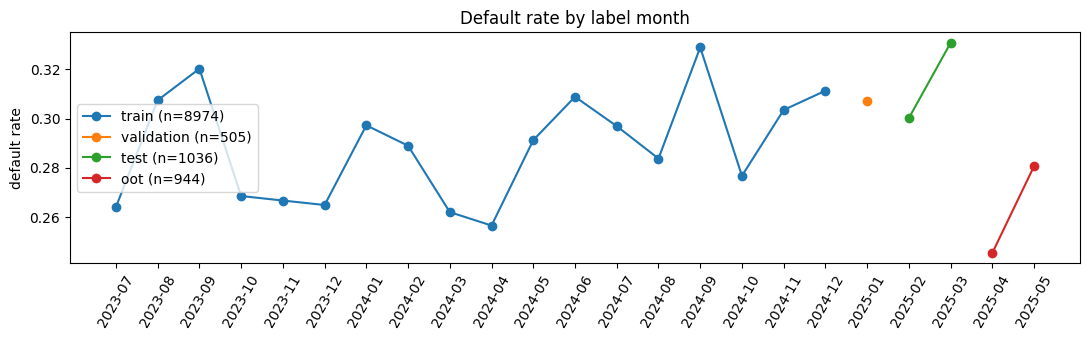

In [12]:
monthly = combined.groupby([combined.labels_snapshot_date.dt.to_period("M"), "data_split"])[TARGET].agg(["mean", "size"]).reset_index()
fig, ax = plt.subplots(figsize=(11, 3.5))
for s in SPLITS:
    m = monthly[monthly.data_split == s]
    ax.plot(m.labels_snapshot_date.astype(str), m["mean"], marker="o", label=f"{s} (n={m['size'].sum()})")
ax.set_ylabel("default rate"); ax.set_title("Default rate by label month"); ax.legend()
plt.xticks(rotation=60); plt.tight_layout(); plt.show()

In [13]:
# Missing share of every column, per split. A feature that is empty in validation/test/oot
# cannot be used at scoring time no matter how predictive it is in train.
missing_by_split = combined.groupby("data_split").apply(lambda d: d.isna().mean(), include_groups=False).T[SPLITS]
missing_by_split[missing_by_split.max(axis=1) > 0].sort_values("validation", ascending=False).round(3)

data_split,train,validation,test,oot
fe_5_mean_90d,0.000,1.000,1.000,1.000
fe_10_mean_90d,0.000,1.000,1.000,1.000
fe_9_mean_90d,0.000,1.000,1.000,1.000
fe_4_mean_90d,0.000,1.000,1.000,1.000
fe_3_mean_90d,0.000,1.000,1.000,1.000
fe_14_trend_30d,0.949,1.000,1.000,1.000
fe_3_std_60d,0.895,1.000,1.000,1.000
fe_8_mean_90d,0.000,1.000,1.000,1.000
fe_1_trend_30d,0.949,1.000,1.000,1.000
fe_16_std_60d,0.895,1.000,1.000,1.000


In [14]:
def collapse_dummies(d, prefix, new_col):
    cols = [c for c in d.columns if c.startswith(prefix)]
    if not cols:
        return d
    vals = d[cols].to_numpy()
    levels = np.array([c[len(prefix):] for c in cols], dtype=object)
    d[new_col] = np.where(vals.sum(axis=1) == 0, None, levels[vals.argmax(axis=1)])
    return d.drop(columns=cols)


def basic_clean(d):
    d = d.copy()
    d = d.loc[:, ~d.columns.duplicated()]
    d["Occupation"] = d["Occupation"].replace("", np.nan).fillna("Unknown")

    for c in NON_NEGATIVE_COLS:
        if c in d.columns:
            d[c] = d[c].clip(lower=0)

    print("Invalid / placeholder values set to NaN:")
    for c, rule in INVALID_VALUE_RULES.items():
        if c in d.columns:
            d[c] = d[c].astype(float)
            mask = rule(d[c])
            print(f"  {c:<25} {int(mask.sum()):>5} rows ({mask.mean():.2%})")
            d[c] = d[c].mask(mask)

    d["Num_Fin_Pdts"] = d["Bank_Accounts_imputed"] + d["Credit_Cards_imputed"] + d["Num_of_Loan_Cleaned"]
    d["InterestRate_x_Debt"] = d["Interest_Rate"] * d["Outstanding_Debt"]

    d = collapse_dummies(d, "Credit_Mix_", "Credit_Mix")
    d = collapse_dummies(d, "Payment_of_Min_Amount_", "Payment_of_Min_Amount")
    return d.drop(columns=[c for c in REDUNDANT_COLS if c in d.columns])


def get_feature_types(d):
    feats = [c for c in d.columns if c not in ID_COLS + [TARGET]]
    cat = [c for c in CATEGORICAL_COLS if c in feats]
    binary = [c for c in feats if c not in cat and d[c].dropna().isin([0, 1]).all()]
    num = [c for c in feats if c not in cat + binary]
    return num, binary, cat



In [16]:
# Share outside train p1/p99 and how extreme the max is -> drives capping.
q = train[num_cols].quantile([0.01, 0.5, 0.99]).T
q.columns = ["p01", "median", "p99"]
prof = q.assign(
    min=train[num_cols].min(), max=train[num_cols].max(),
    missing=train[num_cols].isna().mean(),
    skew=train[num_cols].skew(),
    share_outside_p01_p99=((train[num_cols] < q.p01) | (train[num_cols] > q.p99)).mean(),
    max_over_p99=train[num_cols].max() / q.p99.replace(0, np.nan),
)
prof.sort_values("skew", key=abs, ascending=False).round(3)

,p01,median,p99,min,max,missing,skew,share_outside_p01_p99,max_over_p99
Delayed_Payments_per_Card,0.000,2.429,12.000,0.000,2.508000e+03,0.025,18.960,0.010,209.000
Annual_Income,7518.101,37382.846,178159.702,7006.035,2.383470e+07,0.000,12.732,0.020,133.783
Total_EMI_per_month,0.000,72.520,58075.030,0.000,8.197100e+04,0.000,6.981,0.010,1.411
Debt_per_Credit_Account,3.020,116.078,396.117,0.047,1.496620e+03,0.038,2.898,0.019,3.778
Amount_invested_monthly,17.904,126.240,1010.437,0.000,1.977326e+03,0.044,2.599,0.019,1.957
InterestRate_x_Debt,132.268,10926.320,135499.127,0.770,1.694512e+05,0.022,1.571,0.020,1.251
Monthly_Balance,70.326,338.893,1126.758,0.383,1.460917e+03,0.000,1.560,0.020,1.297
Outstanding_Debt,28.420,1169.190,4808.163,0.230,4.998070e+03,0.000,1.207,0.020,1.039
Monthly_Inhand_Salary,529.973,3074.359,13670.123,319.556,1.516718e+04,0.000,1.123,0.020,1.110
fe_3_std_60d,2.121,69.296,276.054,0.000,3.450680e+02,0.895,1.021,0.002,1.250


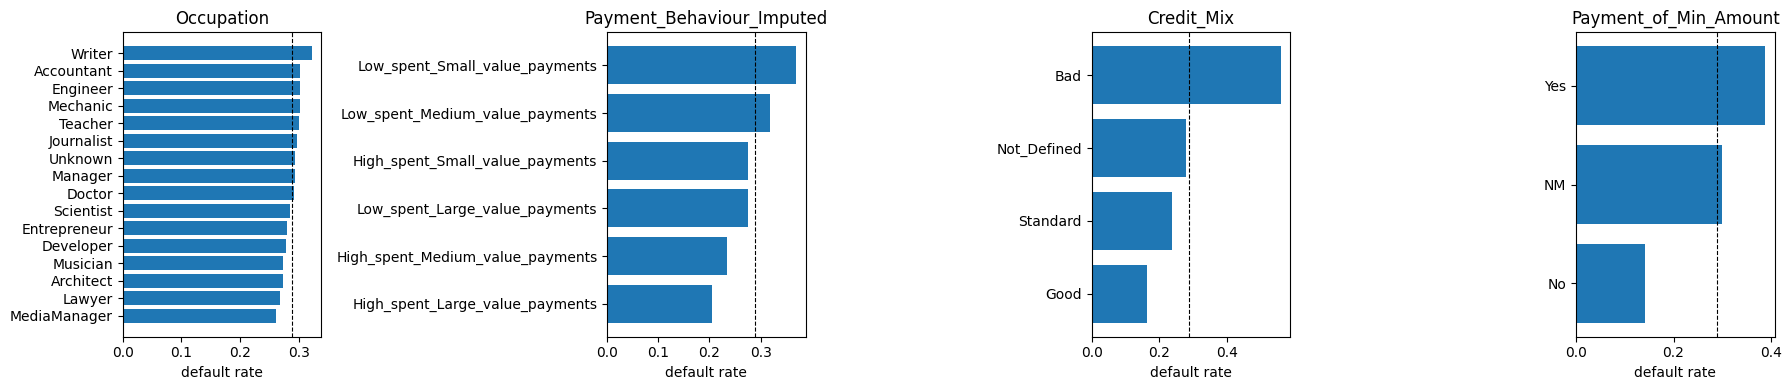

In [17]:
# Default rate by level for each categorical (TRAIN). Big spreads -> strong candidates.
fig, axes = plt.subplots(1, len(cat_cols), figsize=(4.5 * len(cat_cols), 4))
for ax, c in zip(np.atleast_1d(axes), cat_cols):
    t = train.groupby(c)[TARGET].agg(default_rate="mean", n="size").sort_values("default_rate")
    ax.barh(t.index.astype(str), t.default_rate, color="tab:blue")
    ax.axvline(train[TARGET].mean(), color="k", ls="--", lw=0.8)
    ax.set_title(c); ax.set_xlabel("default rate")
plt.tight_layout(); plt.show()

In [18]:
def bin_edges(s, n_bins=10):
    e = np.unique(np.nanquantile(s.dropna(), np.linspace(0, 1, n_bins + 1)))
    if len(e) < 2:
        return None
    e[0], e[-1] = -np.inf, np.inf
    return e


def assign_bins(s, edges, is_cat):
    if is_cat:
        return s.astype("object").fillna("__MISSING__").astype(str)
    b = pd.cut(s, bins=edges, include_lowest=True, duplicates="drop").astype("object")
    return b.where(s.notna(), "__MISSING__").astype(str)


def information_value(bins, y, eps=0.5):
    tab = pd.crosstab(bins, y).reindex(columns=[0, 1], fill_value=0)
    good = (tab[0] + eps) / (tab[0].sum() + eps)
    bad = (tab[1] + eps) / (tab[1].sum() + eps)
    return float(((bad - good) * np.log(bad / good)).sum())


def psi(expected_bins, actual_bins, eps=1e-4):
    e = expected_bins.value_counts(normalize=True)
    a = actual_bins.value_counts(normalize=True)
    idx = e.index.union(a.index)
    e, a = e.reindex(idx, fill_value=0) + eps, a.reindex(idx, fill_value=0) + eps
    return float(((a - e) * np.log(a / e)).sum())


def vif_table(X):
    # VIF_j = 1 / (1 - R^2_j), regressing each standardised column on the others.
    Z = ((X - X.mean()) / X.std(ddof=0).replace(0, 1)).to_numpy()
    out = {}
    for j, c in enumerate(X.columns):
        y = Z[:, j]
        A = np.column_stack([np.ones(len(Z)), np.delete(Z, j, axis=1)])
        coef, *_ = np.linalg.lstsq(A, y, rcond=None)
        r2 = 1 - ((y - A @ coef) ** 2).sum() / max(((y - y.mean()) ** 2).sum(), 1e-12)
        out[c] = np.inf if r2 >= 1 else 1 / (1 - r2)
    return pd.Series(out).sort_values(ascending=False)


def run_feature_selection(d, max_missing=0.5, max_top_share=0.99, min_iv=0.02,
                          max_psi=0.25, max_abs_corr=0.80, max_vif=10.0):
    num, binary, cat = get_feature_types(d)
    feats = num + binary + cat
    tr = d[d.data_split == "train"]
    ev = d[d.data_split.isin(["validation", "test"])]

    rep = pd.DataFrame(index=feats)
    rep["type"] = ["numeric" if f in num else "binary" if f in binary else "categorical" for f in feats]
    rep["missing_train"] = tr[feats].isna().mean()
    rep["missing_val_test"] = ev[feats].isna().mean()
    rep["top_value_share"] = [tr[f].value_counts(normalize=True, dropna=False).iloc[0] for f in feats]
    ivs, psis = {}, {}
    for f in feats:
        is_cat = rep.loc[f, "type"] != "numeric"
        edges = None if is_cat else bin_edges(tr[f])
        if not is_cat and edges is None:          # all-NaN column
            ivs[f], psis[f] = 0.0, np.nan
            continue
        b_tr, b_ev = assign_bins(tr[f], edges, is_cat), assign_bins(ev[f], edges, is_cat)
        ivs[f], psis[f] = information_value(b_tr, tr[TARGET]), psi(b_tr, b_ev)
    rep["iv"], rep["psi_train_vs_valtest"] = pd.Series(ivs), pd.Series(psis)
    rep["drop_reason"] = ""

    def flag(mask, reason):
        rep.loc[mask & (rep.drop_reason == ""), "drop_reason"] = reason

    flag((rep.missing_train > max_missing) | (rep.missing_val_test > max_missing), f"1 missing>{max_missing:.0%}")
    flag(rep.top_value_share > max_top_share, f"2 near-constant")
    flag(rep.iv < min_iv, f"3 IV<{min_iv}")
    flag(rep.psi_train_vs_valtest > max_psi, f"4 PSI>{max_psi}")

    survivors = rep[(rep.drop_reason == "") & (rep.type != "categorical")].sort_values("iv", ascending=False).index
    corr = tr[list(survivors)].corr(method="spearman").abs()
    kept = []
    for f in survivors:
        clash = [k for k in kept if corr.loc[f, k] > max_abs_corr]
        if clash:
            rep.loc[f, "drop_reason"] = f"5 |rho|>{max_abs_corr} with {clash[0]}"
        else:
            kept.append(f)
    xgb_feats = rep.index[rep.drop_reason == ""].tolist()

    rep["vif"], rep["lr_drop_reason"] = np.nan, ""
    X = tr[[f for f in xgb_feats if rep.loc[f, "type"] == "numeric"]]
    X = X.clip(X.quantile(0.01), X.quantile(0.99), axis=1).fillna(X.median())
    while X.shape[1] > 1:
        v = vif_table(X)
        rep.loc[v.index, "vif"] = v
        if v.iloc[0] <= max_vif:
            break
        rep.loc[v.index[0], "lr_drop_reason"] = f"6 VIF={v.iloc[0]:.1f}"
        X = X.drop(columns=v.index[0])
    lr_feats = [f for f in xgb_feats if rep.loc[f, "lr_drop_reason"] == ""]

    rep["iv_strength"] = pd.cut(rep.iv, [-np.inf, 0.02, 0.1, 0.3, 0.5, np.inf],
                                labels=["useless", "weak", "medium", "strong", "very strong - check leakage"])
    rep["selected_xgb"], rep["selected_lr"] = rep.index.isin(xgb_feats), rep.index.isin(lr_feats)
    rep = rep.sort_values(["selected_xgb", "iv"], ascending=[False, False])
    print(f"Candidates {len(feats)} -> XGB {len(xgb_feats)} | LR {len(lr_feats)}")
    print(rep.drop_reason.replace("", "KEPT").str.split(" with ").str[0].value_counts().sort_index().to_string())
    return rep, xgb_feats, lr_feats


report, xgb_features, lr_features = run_feature_selection(df)
report.round(4)

/tmp/ipykernel_1648/1896597810.py:11: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return s.astype("object").fillna("__MISSING__").astype(str)
/tmp/ipykernel_1648/1896597810.py:11: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return s.astype("object").fillna("__MISSING__").astype(str)
/tmp/ipykernel_1648/1896597810.py:11: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.n

Candidates 44 -> XGB 27 | LR 26
drop_reason
1 missing>50%    10
3 IV<0.02         3
5 |rho|>0.8       4
KEPT             27


,type,missing_train,missing_val_test,top_value_share,iv,psi_train_vs_valtest,drop_reason,vif,lr_drop_reason,iv_strength,selected_xgb,selected_lr
InterestRate_x_Debt,numeric,0.0216,0.0253,0.0216,0.9334,0.0062,,4.2041,,very strong - check leakage,True,True
Num_Fin_Pdts,numeric,0.0000,0.0000,0.0781,0.6443,0.0063,,10.4258,6 VIF=10.4,very strong - check leakage,True,False
Num_Credit_Inquiries,numeric,0.0150,0.0175,0.1035,0.5744,0.0098,,1.9427,,very strong - check leakage,True,True
Delay_from_due_date,numeric,0.0000,0.0000,0.0362,0.5635,0.0050,,1.9003,,very strong - check leakage,True,True
Credit_History_Age_Years,numeric,0.0000,0.0000,0.0069,0.4800,0.0094,,2.2189,,strong,True,True
Credit_Cards_imputed,numeric,0.0000,0.0000,0.1986,0.4640,0.0029,,2.5901,,strong,True,True
Credit_Mix,categorical,0.0000,0.0000,0.3569,0.4177,0.0050,,NaN,,strong,True,True
Num_of_Loan_Cleaned,numeric,0.0000,0.0000,0.2278,0.4162,0.0058,,2.3894,,strong,True,True
Payment_of_Min_Amount,categorical,0.0000,0.0000,0.5209,0.3450,0.0056,,NaN,,strong,True,True
Debt_per_Credit_Account,numeric,0.0379,0.0428,0.0379,0.2714,0.0020,,2.0033,,medium,True,True


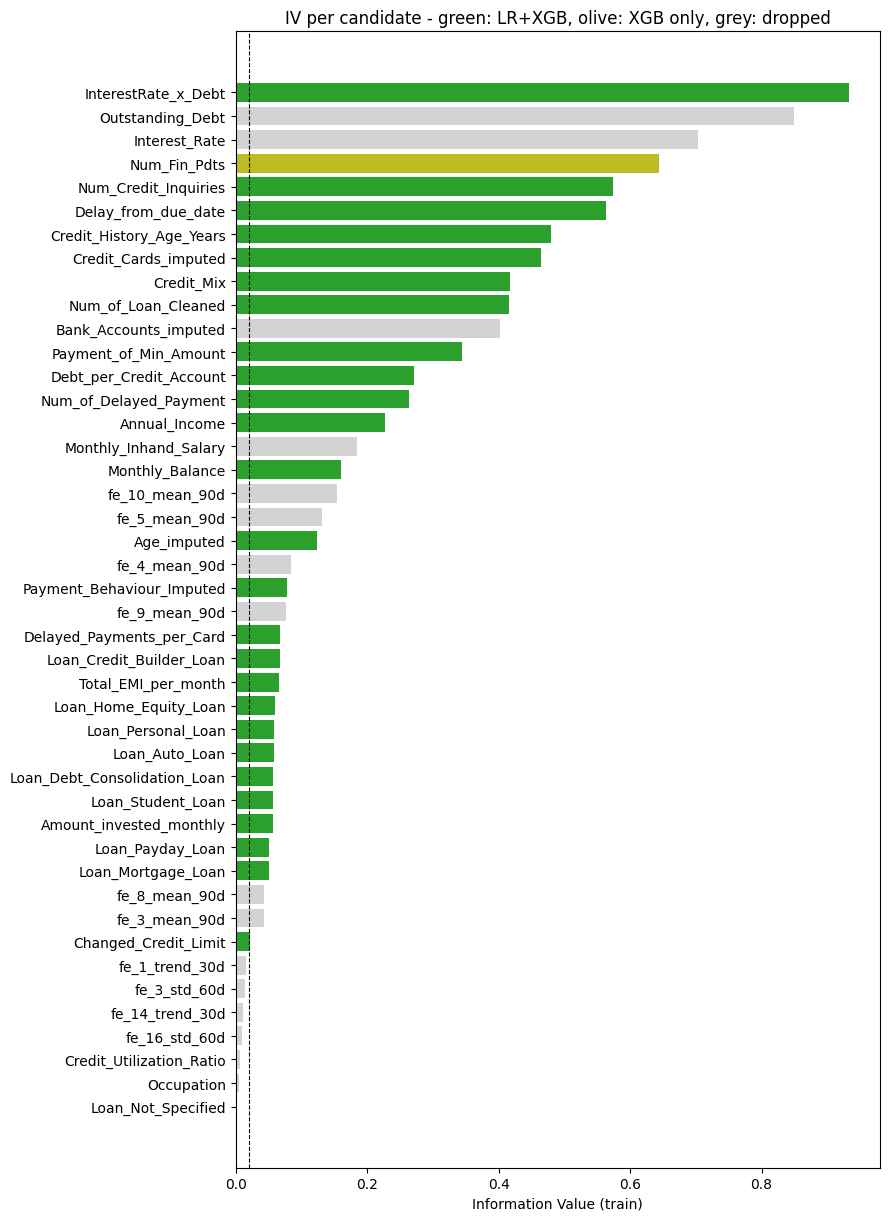

In [19]:
fig, ax = plt.subplots(figsize=(9, max(4, 0.28 * len(report))))
r = report.sort_values("iv")
ax.barh(r.index, r.iv, color=np.where(r.selected_lr, "tab:green", np.where(r.selected_xgb, "tab:olive", "lightgray")))
ax.axvline(0.02, ls="--", c="k", lw=0.8)
ax.set_xlabel("Information Value (train)")
ax.set_title("IV per candidate - green: LR+XGB, olive: XGB only, grey: dropped")
plt.tight_layout(); plt.show()

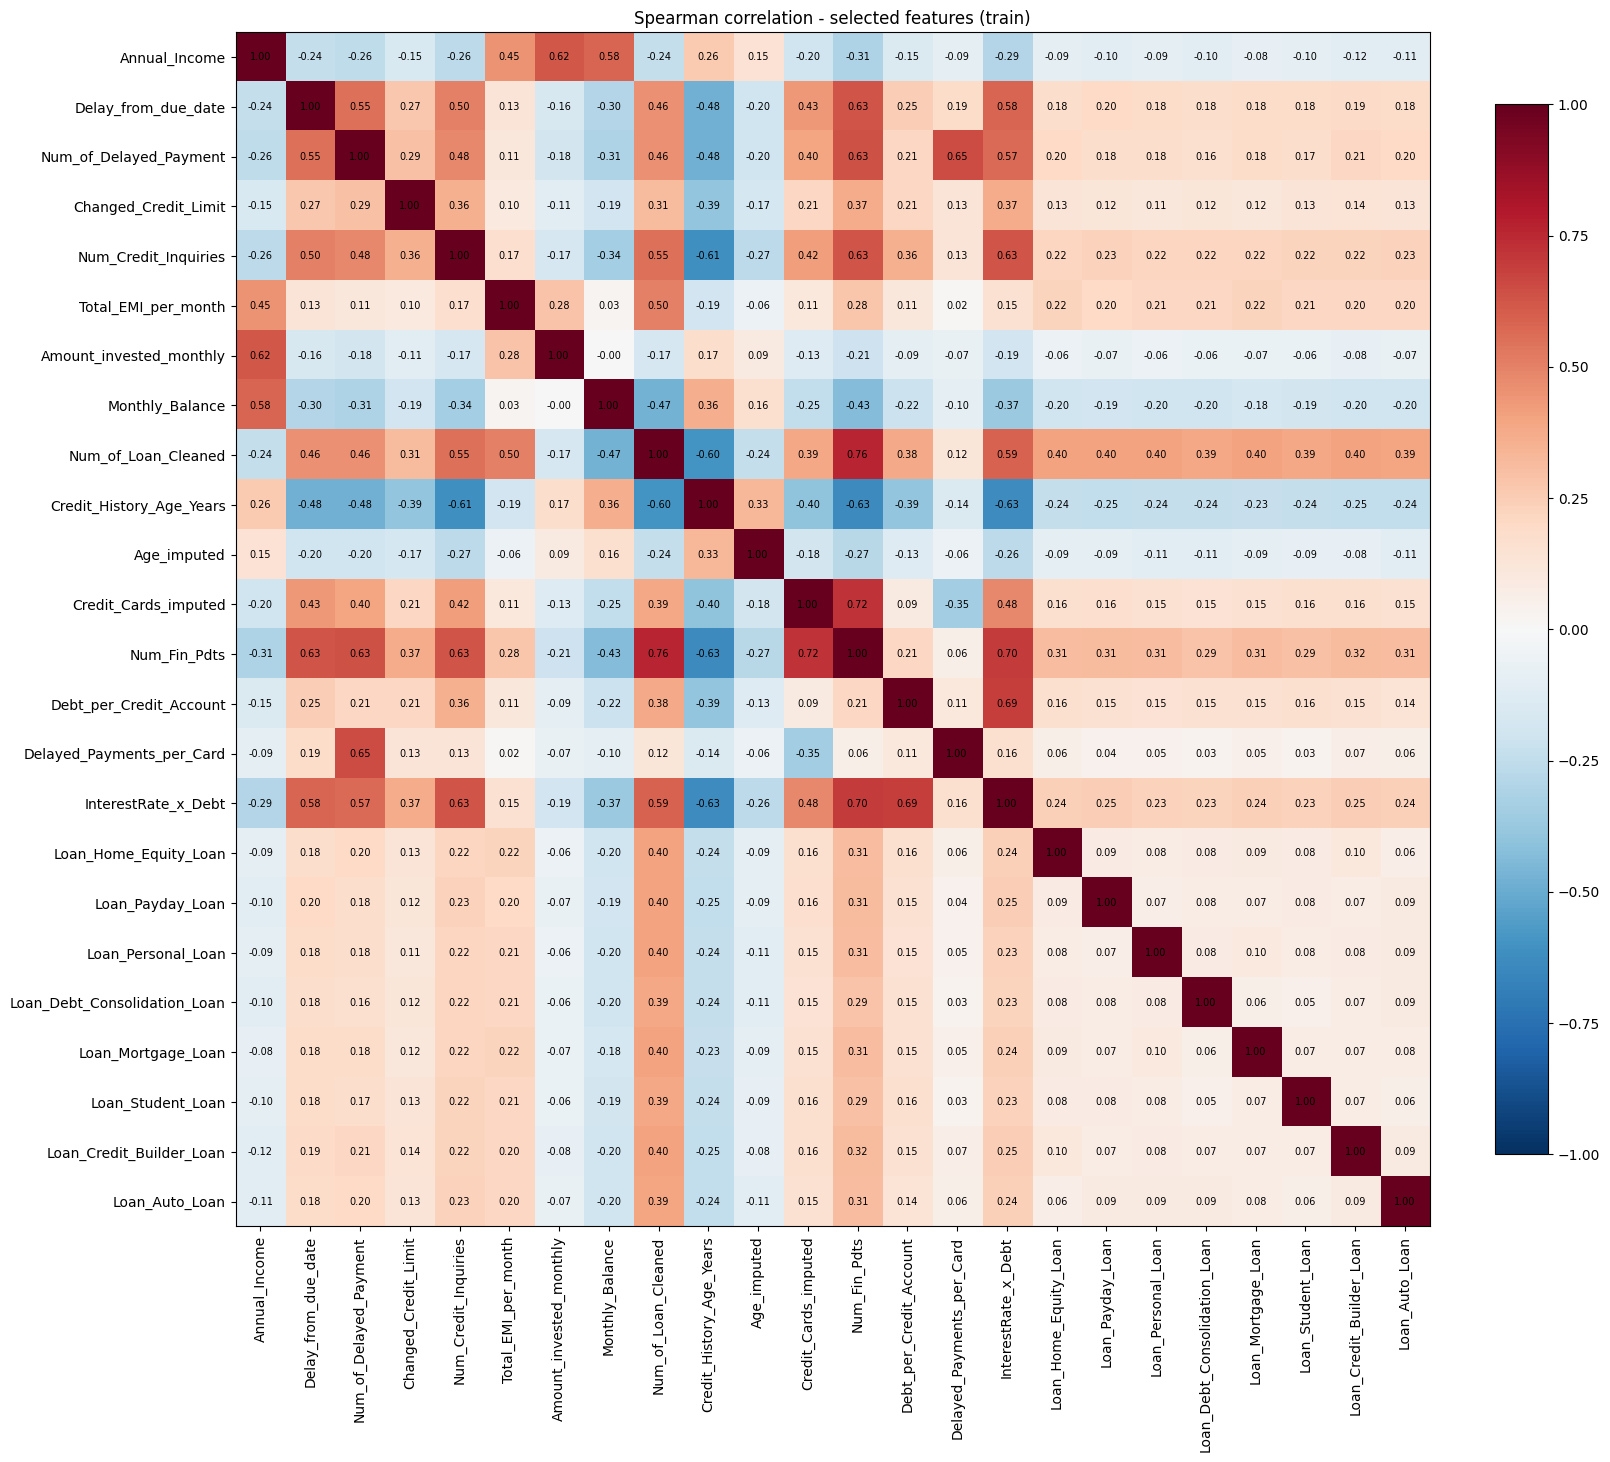

LR features : ['Annual_Income', 'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit', 'Num_Credit_Inquiries', 'Total_EMI_per_month', 'Amount_invested_monthly', 'Monthly_Balance', 'Num_of_Loan_Cleaned', 'Credit_History_Age_Years', 'Age_imputed', 'Credit_Cards_imputed', 'Debt_per_Credit_Account', 'Delayed_Payments_per_Card', 'InterestRate_x_Debt', 'Loan_Home_Equity_Loan', 'Loan_Payday_Loan', 'Loan_Personal_Loan', 'Loan_Debt_Consolidation_Loan', 'Loan_Mortgage_Loan', 'Loan_Student_Loan', 'Loan_Credit_Builder_Loan', 'Loan_Auto_Loan', 'Payment_Behaviour_Imputed', 'Credit_Mix', 'Payment_of_Min_Amount']
XGB features: ['Annual_Income', 'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit', 'Num_Credit_Inquiries', 'Total_EMI_per_month', 'Amount_invested_monthly', 'Monthly_Balance', 'Num_of_Loan_Cleaned', 'Credit_History_Age_Years', 'Age_imputed', 'Credit_Cards_imputed', 'Num_Fin_Pdts', 'Debt_per_Credit_Account', 'Delayed_Payments_per_Card', 'InterestRate_x_D

In [20]:
sel_num = [f for f in xgb_features if f not in cat_cols]
c = train[sel_num].corr(method="spearman")
fig, ax = plt.subplots(figsize=(0.55 * len(sel_num) + 3, 0.55 * len(sel_num) + 2))
im = ax.imshow(c, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(sel_num))); ax.set_xticklabels(sel_num, rotation=90)
ax.set_yticks(range(len(sel_num))); ax.set_yticklabels(sel_num)
for i in range(len(sel_num)):
    for j in range(len(sel_num)):
        ax.text(j, i, f"{c.iat[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, fraction=0.04); ax.set_title("Spearman correlation - selected features (train)")
plt.tight_layout(); plt.show()
print("LR features :", lr_features)
print("XGB features:", xgb_features)

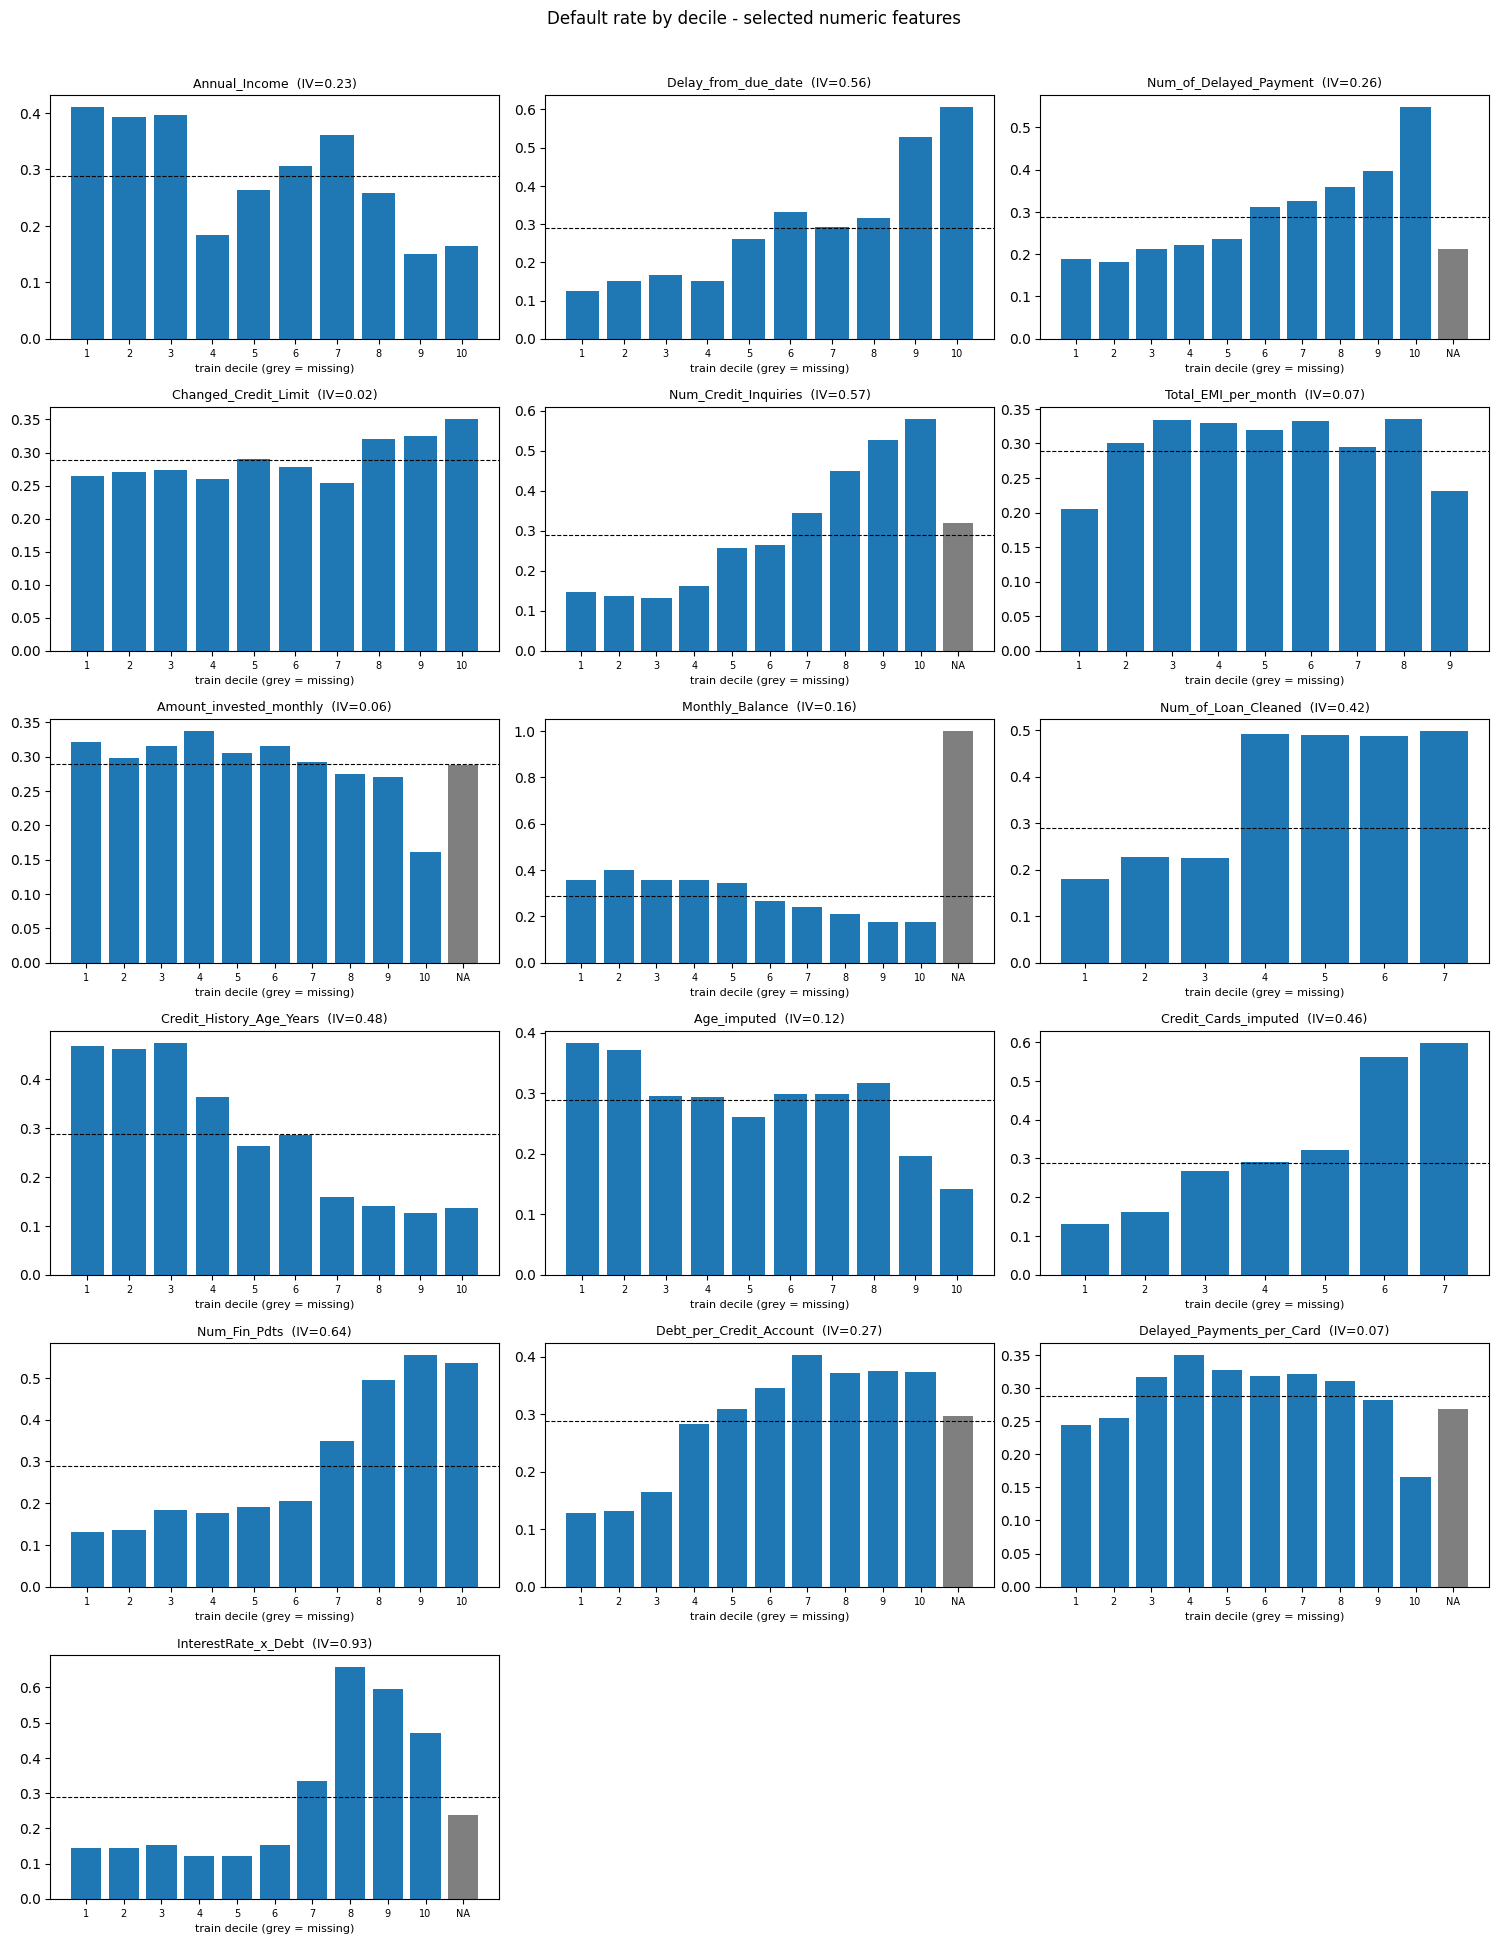

In [21]:
# Default rate by train decile for each selected numeric feature.
# A monotonic shape suits LR; a U-shape means LR needs bins or XGB will capture it better.
sel = [f for f in xgb_features if f in num_cols]
ncol = 3
fig, axes = plt.subplots(int(np.ceil(len(sel) / ncol)), ncol, figsize=(15, 3.2 * np.ceil(len(sel) / ncol)), squeeze=False)
for ax, f in zip(axes.ravel(), sel):
    b = assign_bins(train[f], bin_edges(train[f]), False)
    t = train.groupby(b)[TARGET].agg(["mean", "size"])
    order = sorted([i for i in t.index if i != "__MISSING__"],
                   key=lambda s: float(s.split(",")[0].strip("([ ")))
    order += ["__MISSING__"] if "__MISSING__" in t.index else []
    t = t.loc[order]
    ax.bar(range(len(t)), t["mean"], color=["tab:gray" if i == "__MISSING__" else "tab:blue" for i in t.index])
    ax.axhline(train[TARGET].mean(), color="k", ls="--", lw=0.8)
    ax.set_title(f"{f}  (IV={report.loc[f, 'iv']:.2f})", fontsize=9)
    ax.set_xticks(range(len(t))); ax.set_xticklabels(["NA" if i == "__MISSING__" else str(k + 1) for k, i in enumerate(t.index)], fontsize=7)
    ax.set_xlabel("train decile (grey = missing)", fontsize=8)
for ax in axes.ravel()[len(sel):]:
    ax.axis("off")
plt.suptitle("Default rate by decile - selected numeric features", y=1.01); plt.tight_layout(); plt.show()

## 6. Preprocessing pipelines (fitted on TRAIN only, inside the model pipeline)

| step | LogReg | XGBoost |
|---|---|---|
| outlier capping | winsorise at train p1 / p99 | same (removes residual extremes) |
| skew | signed `log1p` where train \|skew\| > 1 | not needed |
| missing | median + missing-indicator column | left as NaN (native handling) |
| scaling | `StandardScaler` | not needed |
| categoricals | one-hot, first level dropped, levels < 1% pooled | one-hot, levels < 1% pooled |

In [22]:
class QuantileCapper(BaseEstimator, TransformerMixin):
    def __init__(self, lower_q=0.01, upper_q=0.99):
        self.lower_q, self.upper_q = lower_q, upper_q

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.lower_, self.upper_ = X.quantile(self.lower_q).to_numpy(), X.quantile(self.upper_q).to_numpy()
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lower_, self.upper_)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.feature_names_in_ if input_features is None else input_features, dtype=object)


class SkewLogTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, skew_threshold=1.0):
        self.skew_threshold = skew_threshold

    def fit(self, X, y=None):
        self.log_mask_ = (pd.DataFrame(np.asarray(X, dtype=float)).skew().abs() > self.skew_threshold).to_numpy()
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float).copy()
        m = self.log_mask_
        X[:, m] = np.sign(X[:, m]) * np.log1p(np.abs(X[:, m]))
        return X

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)


def build_lr_preprocessor(num, binary, cat):
    numeric = Pipeline([("cap", QuantileCapper(0.01, 0.99)),
                        ("log", SkewLogTransformer(1.0)),
                        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
                        ("scale", StandardScaler())])
    categorical = Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
                            ("ohe", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.01,
                                                  drop="first", sparse_output=False))])
    return ColumnTransformer([("num", numeric, num),
                              ("bin", SimpleImputer(strategy="most_frequent"), binary),
                              ("cat", categorical, cat)], verbose_feature_names_out=False)


def build_xgb_preprocessor(num, binary, cat, categories):
    # categories fixed from TRAIN -> identical output columns in every fold / at scoring.
    # pandas output keeps column names, which XGBoost needs to match monotone_constraints by name.
    categorical = Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
                            ("ohe", OneHotEncoder(categories=categories, handle_unknown="ignore",
                                                  sparse_output=False))])
    return ColumnTransformer([("num", QuantileCapper(0.01, 0.99), num),
                              ("bin", "passthrough", binary),
                              ("cat", categorical, cat)],
                             verbose_feature_names_out=False).set_output(transform="pandas")


def types_of(features):
    return ([f for f in features if f in num_cols], [f for f in features if f in bin_cols],
            [f for f in features if f in cat_cols])


def split_xy(split, features):
    d = df[df.data_split == split].sort_values("labels_snapshot_date")
    return d[features], d[TARGET]

In [23]:
# +1: higher value -> higher default risk | -1: higher value -> lower risk
# One-hot levels use the encoded name "<feature>_<level>".
EXPECTED_DIRECTION = {
    "Delay_from_due_date": +1, "Num_of_Delayed_Payment": +1, "Delayed_Payments_per_Card": +1,
    "Num_Credit_Inquiries": +1, "Outstanding_Debt": +1, "Debt_per_Credit_Account": +1,
    "Interest_Rate": +1, "InterestRate_x_Debt": +1, "Credit_Utilization_Ratio": +1,
    "Total_EMI_per_month": +1, "Num_of_Loan_Cleaned": +1, "Num_Fin_Pdts": +1,
    "Bank_Accounts_imputed": +1, "Credit_Cards_imputed": +1, "Loan_Payday_Loan": +1,
    "Credit_History_Age_Years": -1, "Annual_Income": -1, "Monthly_Inhand_Salary": -1,
    "Monthly_Balance": -1, "Amount_invested_monthly": -1, "Age_imputed": -1,
    "Credit_Mix_Bad": +1, "Credit_Mix_Good": -1,
    "Payment_of_Min_Amount_Yes": +1, "Payment_of_Min_Amount_No": -1,
}
CONFLICT_POLICY = "prior"          # "prior" or "data"


def decile_trend(s, y):
    e = bin_edges(s)
    if e is None:
        return np.nan
    r = y.groupby(pd.cut(s, e, include_lowest=True, duplicates="drop"), observed=True).mean()
    return float(pd.Series(np.arange(len(r))).corr(pd.Series(r.to_numpy()), method="spearman")) if len(r) >= 3 else np.nan


xgb_num, xgb_bin, xgb_cat = types_of(xgb_features)
xgb_categories = [sorted(train[c].fillna("Unknown").astype(str).unique()) for c in xgb_cat]

rows = []
for f in xgb_num + xgb_bin:
    rho = train[f].corr(train[TARGET], method="spearman")
    rows.append({"model_input": f, "source_feature": f, "kind": "numeric" if f in xgb_num else "binary",
                 "train_spearman": rho, "decile_trend": decile_trend(train[f], train[TARGET]) if f in xgb_num else np.nan,
                 "level_minus_rest_rate": np.nan, "data_direction": int(np.sign(rho))})
for f, levels in zip(xgb_cat, xgb_categories):
    s = train[f].fillna("Unknown").astype(str)
    for lvl in levels:
        m = s == lvl
        diff = train.loc[m, TARGET].mean() - train.loc[~m, TARGET].mean()
        rows.append({"model_input": f"{f}_{lvl}", "source_feature": f, "kind": "one-hot level",
                     "train_spearman": np.nan, "decile_trend": np.nan, "level_minus_rest_rate": diff,
                     "data_direction": int(np.sign(diff))})

dir_tbl = pd.DataFrame(rows).set_index("model_input")
dir_tbl["prior"] = dir_tbl.index.map(EXPECTED_DIRECTION)
dir_tbl["conflict"] = dir_tbl.prior.notna() & (dir_tbl.data_direction != 0) & (dir_tbl.prior != dir_tbl.data_direction)
primary, fallback = (dir_tbl.prior, dir_tbl.data_direction) if CONFLICT_POLICY == "prior" else (dir_tbl.data_direction.replace(0, np.nan), dir_tbl.prior)
dir_tbl["constraint"] = primary.fillna(fallback).fillna(0).astype(int)
dir_tbl["source"] = np.where(dir_tbl.prior.notna() & (CONFLICT_POLICY == "prior"), "prior", "train data")
dir_tbl["non_monotone_shape"] = dir_tbl.decile_trend.abs() < 0.6

xgb_monotone = {k: int(v) for k, v in dir_tbl.constraint.items()}
print(f"{len(xgb_monotone)} XGB inputs | +1: {sum(v == 1 for v in xgb_monotone.values())} "
      f"| -1: {sum(v == -1 for v in xgb_monotone.values())} | unconstrained: {sum(v == 0 for v in xgb_monotone.values())}")
if dir_tbl.conflict.any():
    print("PRIOR vs DATA CONFLICTS (review):", dir_tbl.index[dir_tbl.conflict].tolist())
if dir_tbl.non_monotone_shape.any():
    print("Non-monotone decile shape:", dir_tbl.index[dir_tbl.non_monotone_shape].tolist())
dir_tbl.round(4)

37 XGB inputs | +1: 24 | -1: 13 | unconstrained: 0
PRIOR vs DATA CONFLICTS (review): ['Delayed_Payments_per_Card']
Non-monotone decile shape: ['Total_EMI_per_month', 'Delayed_Payments_per_Card']


,source_feature,kind,train_spearman,decile_trend,level_minus_rest_rate,data_direction,prior,conflict,constraint,source,non_monotone_shape
model_input,,,,,,,,,,,
Annual_Income,Annual_Income,numeric,-0.1578,-0.8061,NaN,-1,-1.0,False,-1,prior,False
Delay_from_due_date,Delay_from_due_date,numeric,0.3138,0.9273,NaN,1,1.0,False,1,prior,False
Num_of_Delayed_Payment,Num_of_Delayed_Payment,numeric,0.2191,0.9879,NaN,1,1.0,False,1,prior,False
Changed_Credit_Limit,Changed_Credit_Limit,numeric,0.0533,0.6606,NaN,1,NaN,False,1,train data,False
Num_Credit_Inquiries,Num_Credit_Inquiries,numeric,0.3256,0.9515,NaN,1,1.0,False,1,prior,False
Total_EMI_per_month,Total_EMI_per_month,numeric,0.0476,0.1667,NaN,1,1.0,False,1,prior,True
Amount_invested_monthly,Amount_invested_monthly,numeric,-0.0772,-0.8024,NaN,-1,-1.0,False,-1,prior,False
Monthly_Balance,Monthly_Balance,numeric,-0.1686,-0.9273,NaN,-1,-1.0,False,-1,prior,False
Num_of_Loan_Cleaned,Num_of_Loan_Cleaned,numeric,0.2744,0.8214,NaN,1,1.0,False,1,prior,False


## 7. Time-aware CV inside TRAIN
Validation is one month (~500 rows) - too small to rank many hyper-parameter sets reliably.
Hyper-parameters are chosen by **expanding-window CV over train months** (fit on earlier months, score the next 2).
Validation is then used only for XGB early stopping and the decision threshold.

In [24]:
def monthly_expanding_splits(dates, n_splits=4, val_months=2):
    months = pd.Series(pd.to_datetime(dates)).dt.to_period("M").to_numpy()
    uniq = np.sort(pd.unique(months))
    splits = []
    for i in range(n_splits, 0, -1):
        cut = len(uniq) - i * val_months
        if cut < 3:
            continue
        splits.append((np.where(np.isin(months, uniq[:cut]))[0],
                       np.where(np.isin(months, uniq[cut:cut + val_months]))[0]))
        print(f"  fold {len(splits)}: fit {uniq[0]}..{uniq[cut - 1]} ({len(splits[-1][0])} rows) "
              f"-> score {uniq[cut]}..{uniq[min(cut + val_months, len(uniq)) - 1]} ({len(splits[-1][1])} rows)")
    return splits


train_sorted = df[df.data_split == "train"].sort_values("labels_snapshot_date").reset_index(drop=True)
y_tr = train_sorted[TARGET]
cv_splits = monthly_expanding_splits(train_sorted.labels_snapshot_date, n_splits=4, val_months=2)

  fold 1: fit 2023-07..2024-04 (4978 rows) -> score 2024-05..2024-06 (980 rows)
  fold 2: fit 2023-07..2024-06 (5958 rows) -> score 2024-07..2024-08 (1003 rows)
  fold 3: fit 2023-07..2024-08 (6961 rows) -> score 2024-09..2024-10 (1024 rows)
  fold 4: fit 2023-07..2024-10 (7985 rows) -> score 2024-11..2024-12 (989 rows)


### Model Training
# Log Reg

In [25]:
lr_num, lr_bin, lr_cat = types_of(lr_features)
lr_pipe = Pipeline([("pre", build_lr_preprocessor(lr_num, lr_bin, lr_cat)),
                    ("model", LogisticRegression(solver="liblinear", max_iter=5000, random_state=RANDOM_STATE))])

lr_grid = {"model__C": np.logspace(-3, 1, 9), "model__class_weight": [None, "balanced"]}
if tuple(int(x) for x in sklearn.__version__.split(".")[:2]) >= (1, 8):
    lr_grid["model__l1_ratio"] = [0.0, 1.0]        # sklearn >= 1.8: 0 = L2, 1 = L1
else:
    lr_grid["model__penalty"] = ["l2", "l1"]

lr_search = GridSearchCV(lr_pipe, lr_grid, scoring="roc_auc", cv=cv_splits, n_jobs=-1, refit=True)
lr_search.fit(train_sorted[lr_features], y_tr)
lr_model = lr_search.best_estimator_
print(f"LR best CV AUC = {lr_search.best_score_:.4f}  params = {lr_search.best_params_}")

cv_res = pd.DataFrame(lr_search.cv_results_).sort_values("rank_test_score")
cv_res[[c for c in cv_res.columns if c.startswith("param_")] + ["mean_test_score", "std_test_score"]].head(8)

LR best CV AUC = 0.7653  params = {'model__C': np.float64(3.1622776601683795), 'model__class_weight': 'balanced', 'model__penalty': 'l2'}


,param_model__C,param_model__class_weight,param_model__penalty,mean_test_score,std_test_score
30,3.162278,balanced,l2,0.765333,0.012110
34,10.000000,balanced,l2,0.765322,0.012178
35,10.000000,balanced,l1,0.765313,0.012140
31,3.162278,balanced,l1,0.765273,0.012062
26,1.000000,balanced,l2,0.765270,0.012006
27,1.000000,balanced,l1,0.765206,0.012006
22,0.316228,balanced,l2,0.765141,0.011975
32,10.000000,None,l2,0.765119,0.012192


In [26]:
ENFORCE_LR_SIGNS = True
lr_expected = dir_tbl.constraint.to_dict()


def lr_sign_table(model, feats):
    pre = model.named_steps["pre"]
    coef = pd.Series(model.named_steps["model"].coef_.ravel(), index=pre.get_feature_names_out())
    rows = [{"model_input": f, "kind": "numeric/binary", "expected": lr_expected[f], "coef_per_1sd": coef[f]}
            for f in feats if f in coef.index and f in lr_expected]
    n, b, c = types_of(feats)
    if c:
        ohe = pre.named_transformers_["cat"].named_steps["ohe"]
        for j, col in enumerate(c):
            ref = ohe.categories_[j][ohe.drop_idx_[j]]
            s = train[col].fillna("Unknown").astype(str)
            ref_rate = train.loc[s == ref, TARGET].mean()
            for lvl in ohe.categories_[j]:
                name = f"{col}_{lvl}"
                if lvl == ref or name not in coef.index:
                    continue
                rows.append({"model_input": name, "kind": f"level vs ref '{ref}'",
                             "expected": int(np.sign(train.loc[s == lvl, TARGET].mean() - ref_rate)),
                             "coef_per_1sd": coef[name]})
    t = pd.DataFrame(rows)
    t["sign_ok"] = (np.sign(t.coef_per_1sd) == 0) | (np.sign(t.coef_per_1sd) == t.expected)
    return t


def val_auc(model, feats):
    X, y = split_xy("validation", feats)
    return roc_auc_score(y, model.predict_proba(X)[:, 1])


auc_before = val_auc(lr_model, lr_features)
dropped_for_sign = []
while ENFORCE_LR_SIGNS:
    t = lr_sign_table(lr_model, lr_features)
    bad = t[(~t.sign_ok) & (t.kind == "numeric/binary")]
    if bad.empty:
        break
    worst = report.loc[bad.model_input, "iv"].idxmin()
    dropped_for_sign.append({"feature": worst, "coef": float(bad.set_index("model_input").coef_per_1sd[worst]),
                             "expected": int(lr_expected[worst])})
    lr_features = [f for f in lr_features if f != worst]
    n, b, c = types_of(lr_features)
    lr_model = (Pipeline([("pre", build_lr_preprocessor(n, b, c)),
                          ("model", LogisticRegression(solver="liblinear", max_iter=5000, random_state=RANDOM_STATE))])
                .set_params(**lr_search.best_params_).fit(train_sorted[lr_features], y_tr))

lr_num, lr_bin, lr_cat = types_of(lr_features)
print("dropped for wrong sign:", dropped_for_sign or "none")
print(f"validation AUC: before {auc_before:.4f} -> after {val_auc(lr_model, lr_features):.4f}")
print("final LR features:", lr_features)
lr_sign_tbl = lr_sign_table(lr_model, lr_features)
lr_sign_tbl.round(4)

dropped for wrong sign: [{'feature': 'Changed_Credit_Limit', 'coef': -0.32614995988669887, 'expected': 1}, {'feature': 'Total_EMI_per_month', 'coef': -0.027221971850044446, 'expected': 1}, {'feature': 'Delayed_Payments_per_Card', 'coef': -0.2767685461883058, 'expected': 1}, {'feature': 'Monthly_Balance', 'coef': 0.2602641417859714, 'expected': -1}, {'feature': 'Annual_Income', 'coef': 0.08552388982152281, 'expected': -1}, {'feature': 'Loan_Payday_Loan', 'coef': -0.0002676969394044048, 'expected': 1}, {'feature': 'Num_of_Delayed_Payment', 'coef': -0.170388884039506, 'expected': 1}, {'feature': 'Debt_per_Credit_Account', 'coef': -0.03570216419709876, 'expected': 1}, {'feature': 'Num_of_Loan_Cleaned', 'coef': -0.07831772208597611, 'expected': 1}, {'feature': 'Loan_Mortgage_Loan', 'coef': -0.001345591710276553, 'expected': 1}]
validation AUC: before 0.7557 -> after 0.7362
final LR features: ['Delay_from_due_date', 'Num_Credit_Inquiries', 'Amount_invested_monthly', 'Credit_History_Age_Years

,model_input,kind,expected,coef_per_1sd,sign_ok
0,Delay_from_due_date,numeric/binary,1,0.2866,True
1,Num_Credit_Inquiries,numeric/binary,1,0.2413,True
2,Amount_invested_monthly,numeric/binary,-1,-0.0726,True
3,Credit_History_Age_Years,numeric/binary,-1,-0.0641,True
4,Age_imputed,numeric/binary,-1,-0.0346,True
5,Credit_Cards_imputed,numeric/binary,1,0.2859,True
6,InterestRate_x_Debt,numeric/binary,1,0.3295,True
7,Loan_Home_Equity_Loan,numeric/binary,1,0.0517,True
8,Loan_Personal_Loan,numeric/binary,1,0.0420,True
9,Loan_Debt_Consolidation_Loan,numeric/binary,1,0.0320,True


# XGBoost

In [27]:
xgb_pipe = Pipeline([("pre", build_xgb_preprocessor(xgb_num, xgb_bin, xgb_cat, xgb_categories)),
                     ("model", XGBClassifier(tree_method="hist", eval_metric="auc",
                                             monotone_constraints=xgb_monotone,
                                             random_state=RANDOM_STATE, n_jobs=-1))])
xgb_dist = {"model__n_estimators": [200, 300, 500, 800],
            "model__learning_rate": [0.01, 0.02, 0.05, 0.1],
            "model__max_depth": [2, 3, 4, 5],
            "model__min_child_weight": [1, 5, 10, 20],
            "model__subsample": [0.6, 0.7, 0.8, 1.0],
            "model__colsample_bytree": [0.5, 0.7, 0.8, 1.0],
            "model__reg_lambda": [1, 5, 10, 20],
            "model__reg_alpha": [0, 0.1, 1],
            "model__gamma": [0, 0.5, 1]}
xgb_search = RandomizedSearchCV(xgb_pipe, xgb_dist, n_iter=40, scoring="roc_auc", cv=cv_splits,
                                n_jobs=-1, random_state=RANDOM_STATE, refit=False)
xgb_search.fit(train_sorted[xgb_features], y_tr)
print(f"XGB best CV AUC = {xgb_search.best_score_:.4f}\nparams = {xgb_search.best_params_}")

XGB best CV AUC = 0.7724
params = {'model__subsample': 1.0, 'model__reg_lambda': 1, 'model__reg_alpha': 1, 'model__n_estimators': 800, 'model__min_child_weight': 1, 'model__max_depth': 5, 'model__learning_rate': 0.1, 'model__gamma': 1, 'model__colsample_bytree': 1.0}


In [28]:
# Refit on all train; validation decides the number of trees.
best = {k.replace("model__", ""): v for k, v in xgb_search.best_params_.items() if k != "model__n_estimators"}
xgb_pre = build_xgb_preprocessor(xgb_num, xgb_bin, xgb_cat, xgb_categories).fit(train_sorted[xgb_features], y_tr)
assert set(xgb_monotone) == set(xgb_pre.get_feature_names_out()), "constraint names must match encoded columns"
X_val_x, y_val = split_xy("validation", xgb_features)

xgb_clf = XGBClassifier(**best, n_estimators=3000, early_stopping_rounds=100, tree_method="hist",
                        eval_metric="auc", monotone_constraints=xgb_monotone,
                        random_state=RANDOM_STATE, n_jobs=-1)
xgb_clf.fit(xgb_pre.transform(train_sorted[xgb_features]), y_tr,
            eval_set=[(xgb_pre.transform(X_val_x), y_val)], verbose=False)
xgb_model = Pipeline([("pre", xgb_pre), ("model", xgb_clf)])
print(f"best_iteration = {xgb_clf.best_iteration} | validation AUC = {xgb_clf.best_score:.4f}")
print("constraints inside booster:", json.loads(xgb_clf.get_booster().save_config())
      ["learner"]["gradient_booster"]["tree_train_param"]["monotone_constraints"])

best_iteration = 26 | validation AUC = 0.7877
constraints inside booster: (-1,1,1,1,1,1,-1,-1,1,-1,-1,1,1,1,1,1,1,1,1,1,1,1,1,1,-1,-1,-1,-1,1,1,1,-1,-1,-1,1,-1,1)


## 9b. Verify monotonicity of the fitted XGBoost
For 300 OOT rows, each input is swept across its train range while every other input stays fixed (ICE curves).
The log-odds must never move against the constraint: `rows_violating` must be 0 for every input.
`avg_logodds_change_min_to_max` is the signed effect of moving an input from its train min to max, comparable in
spirit to an LR coefficient: the sign gives the direction and the size gives the magnitude.

In [29]:
def monotonicity_check(pre, clf, X_raw, constraints, n_rows=300, n_grid=20):
    Xs = pre.transform(X_raw.sample(min(n_rows, len(X_raw)), random_state=RANDOM_STATE)).reset_index(drop=True)
    Xtr = pre.transform(train_sorted[xgb_features])
    booster, it = clf.get_booster(), (0, clf.best_iteration + 1)
    out, curves = [], {}
    for name, c in constraints.items():
        grid = np.unique(np.nanquantile(Xtr[name].astype(float), np.linspace(0, 1, n_grid)))
        if len(grid) < 2:
            continue
        P = np.vstack([booster.predict(xgb.DMatrix(Xs.assign(**{name: g})), output_margin=True, iteration_range=it)
                       for g in grid])                        # shape: grid x rows
        step = np.diff(P, axis=0) * (c if c != 0 else 1)
        out.append({"model_input": name, "constraint": c,
                    "rows_violating": float((step < -1e-6).any(axis=0).mean()) if c != 0 else np.nan,
                    "avg_logodds_change_min_to_max": float((P[-1] - P[0]).mean())})
        curves[name] = (grid, P.mean(axis=1))
    return pd.DataFrame(out).set_index("model_input"), curves


X_oot_x, _ = split_xy("oot", xgb_features)
mono_check, pd_curves = monotonicity_check(xgb_pre, xgb_clf, X_oot_x, xgb_monotone)
n_bad = int((mono_check.rows_violating > 0).sum())
print("MONOTONICITY VERIFIED for all constrained inputs" if n_bad == 0 else f"{n_bad} inputs violate their constraint!")
mono_check.sort_values("avg_logodds_change_min_to_max", key=abs, ascending=False).round(4)

MONOTONICITY VERIFIED for all constrained inputs


,constraint,rows_violating,avg_logodds_change_min_to_max
model_input,,,
InterestRate_x_Debt,1,0.0,1.4193
Credit_Cards_imputed,1,0.0,1.1017
Delay_from_due_date,1,0.0,0.4839
Amount_invested_monthly,-1,0.0,-0.3240
Credit_Mix_Standard,-1,0.0,-0.2394
Payment_Behaviour_Imputed_Low_spent_Small_value_payments,1,0.0,0.1803
Debt_per_Credit_Account,1,0.0,0.1777
Credit_History_Age_Years,-1,0.0,-0.1276
Num_Credit_Inquiries,1,0.0,0.1260


### Evaluation

In [30]:
def ks_stat(y, p):
    fpr, tpr, _ = roc_curve(y, p)
    return float(np.max(tpr - fpr))


def youden_threshold(y, p):
    fpr, tpr, thr = roc_curve(y, p)
    return float(thr[np.argmax(tpr - fpr)])


def evaluate(model, features, threshold, name):
    rows = []
    for s in SPLITS:
        X, y = split_xy(s, features)
        p = model.predict_proba(X)[:, 1]
        yhat = (p >= threshold).astype(int)
        auc = roc_auc_score(y, p)
        rows.append({"model": name, "split": s, "n": len(y), "default_rate": y.mean(), "AUC": auc,
                     "Gini": 2 * auc - 1, "KS": ks_stat(y, p), "PR_AUC": average_precision_score(y, p),
                     "Brier": brier_score_loss(y, p), "LogLoss": log_loss(y, p), "threshold": threshold,
                     "Precision": precision_score(y, yhat, zero_division=0),
                     "Recall": recall_score(y, yhat), "F1": f1_score(y, yhat)})
    return pd.DataFrame(rows)


MODELS = [("LogReg", lr_model, lr_features), ("XGBoost", xgb_model, xgb_features)]
thresholds = {}
for name, model, feats in MODELS:
    Xv, yv = split_xy("validation", feats)
    thresholds[name] = youden_threshold(yv, model.predict_proba(Xv)[:, 1])

metrics = pd.concat([evaluate(m, f, thresholds[n], n) for n, m, f in MODELS], ignore_index=True)
print("thresholds:", {k: round(v, 4) for k, v in thresholds.items()})
display(metrics.round(4))
metrics.pivot(index="split", columns="model", values=["AUC", "Gini", "KS"]).reindex(SPLITS).round(4)

thresholds: {'LogReg': 0.4794, 'XGBoost': 0.2283}


,model,split,n,default_rate,AUC,Gini,KS,PR_AUC,Brier,LogLoss,threshold,Precision,Recall,F1
0,LogReg,train,8974,0.2887,0.7611,0.5223,0.4525,0.5340,0.1960,0.5831,0.4794,0.5291,0.7020,0.6034
1,LogReg,validation,505,0.3069,0.7362,0.4724,0.4210,0.4885,0.2096,0.6158,0.4794,0.5354,0.6839,0.6006
2,LogReg,test,1036,0.3147,0.7587,0.5175,0.4637,0.5233,0.2008,0.5970,0.4794,0.5531,0.7025,0.6189
3,LogReg,oot,944,0.2638,0.7609,0.5217,0.4798,0.4849,0.1998,0.5945,0.4794,0.4890,0.7149,0.5808
4,XGBoost,train,8974,0.2887,0.7972,0.5943,0.4943,0.5943,0.1575,0.4816,0.2283,0.5335,0.7561,0.6256
5,XGBoost,validation,505,0.3069,0.7877,0.5754,0.5020,0.5725,0.1660,0.4994,0.2283,0.5613,0.7677,0.6485
6,XGBoost,test,1036,0.3147,0.7788,0.5575,0.4748,0.5593,0.1703,0.5128,0.2283,0.5467,0.7362,0.6275
7,XGBoost,oot,944,0.2638,0.7861,0.5721,0.5314,0.5392,0.1487,0.4632,0.2283,0.5080,0.7671,0.6112


AUC            Gini              KS        
model       LogReg XGBoost  LogReg XGBoost  LogReg XGBoost
split                                                     
train       0.7611  0.7972  0.5223  0.5943  0.4525  0.4943
validation  0.7362  0.7877  0.4724  0.5754  0.4210  0.5020
test        0.7587  0.7788  0.5175  0.5575  0.4637  0.4748
oot         0.7609  0.7861  0.5217  0.5721  0.4798  0.5314

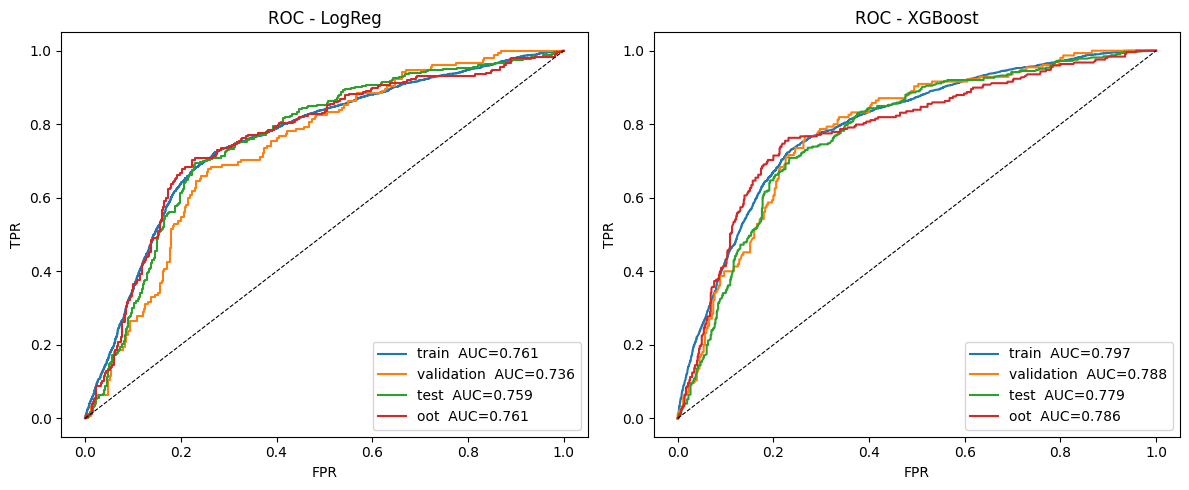

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, model, feats) in zip(axes, MODELS):
    for s in SPLITS:
        X, y = split_xy(s, feats)
        p = model.predict_proba(X)[:, 1]
        fpr, tpr, _ = roc_curve(y, p)
        ax.plot(fpr, tpr, label=f"{s}  AUC={roc_auc_score(y, p):.3f}")
    ax.plot([0, 1], [0, 1], "k--", lw=0.8)
    ax.set_title(f"ROC - {name}"); ax.set_xlabel("FPR"); ax.set_ylabel("TPR"); ax.legend()
plt.tight_layout(); plt.show()

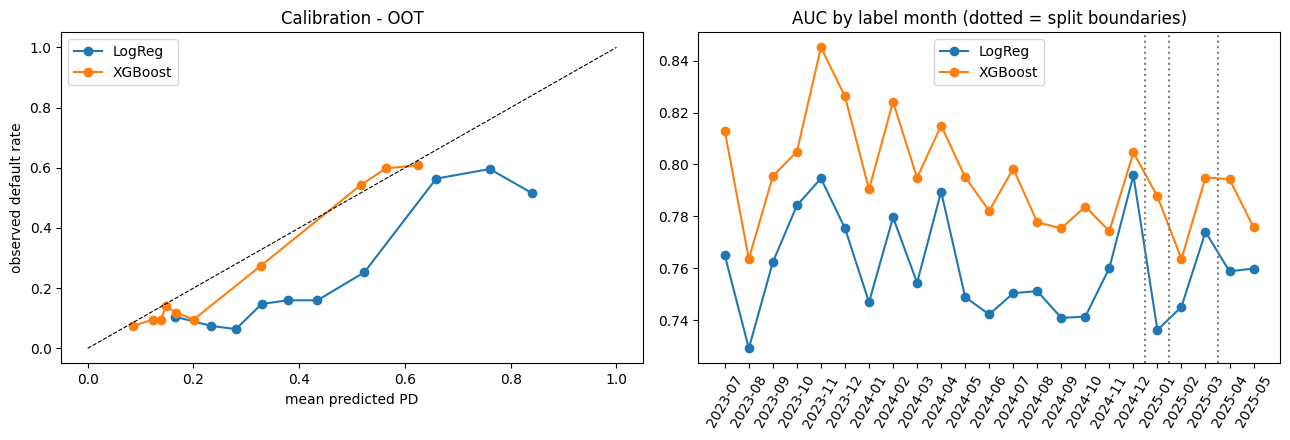

In [32]:
# Calibration on OOT, and AUC month by month across all four splits
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, model, feats in MODELS:
    X, y = split_xy("oot", feats)
    frac_pos, mean_pred = calibration_curve(y, model.predict_proba(X)[:, 1], n_bins=10, strategy="quantile")
    axes[0].plot(mean_pred, frac_pos, marker="o", label=name)

    rows = []
    for m, d in df.groupby(df.labels_snapshot_date.dt.to_period("M")):
        if d[TARGET].nunique() == 2:
            rows.append((str(m), roc_auc_score(d[TARGET], model.predict_proba(d[feats])[:, 1])))
    months, aucs = zip(*rows)
    axes[1].plot(months, aucs, marker="o", label=name)
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8); axes[0].set_title("Calibration - OOT")
axes[0].set_xlabel("mean predicted PD"); axes[0].set_ylabel("observed default rate"); axes[0].legend()
for b in ["2025-01", "2025-02", "2025-04"]:
    if b in months:
        axes[1].axvline(months.index(b) - 0.5, color="gray", ls=":")
axes[1].set_title("AUC by label month (dotted = split boundaries)"); axes[1].tick_params(axis="x", rotation=60)
axes[1].legend(); plt.tight_layout(); plt.show()

In [33]:
# Score stability: PSI of predicted PD, train vs each later split (< 0.1 stable, 0.1-0.25 watch, > 0.25 shift)
rows = []
for name, model, feats in MODELS:
    s_tr = pd.Series(model.predict_proba(train_sorted[feats])[:, 1])
    e = bin_edges(s_tr)
    for s in ["validation", "test", "oot"]:
        X, _ = split_xy(s, feats)
        rows.append({"model": name, "split": s,
                     "score_PSI": psi(assign_bins(s_tr, e, False),
                                      assign_bins(pd.Series(model.predict_proba(X)[:, 1]), e, False))})
pd.DataFrame(rows).pivot(index="split", columns="model", values="score_PSI").reindex(["validation", "test", "oot"]).round(4)

model,LogReg,XGBoost
split,,
validation,0.0110,0.0281
test,0.0080,0.0161
oot,0.0089,0.0042


### Explainability

- **LogReg**: coefficient per 1 SD of the (capped / logged) feature and odds ratio (OR > 1 → riskier).
- **XGBoost**: mean |SHAP| on OOT via XGBoost's native TreeSHAP (`pred_contribs`, no `shap` package);
  `direction` > 0 means higher feature values push towards default.

In [34]:
names = lr_model.named_steps["pre"].get_feature_names_out()
coef = lr_model.named_steps["model"].coef_.ravel()
lr_coef = (pd.DataFrame({"feature": names, "coef_per_1sd": coef, "odds_ratio": np.exp(coef)})
           .merge(lr_sign_tbl[["model_input", "expected", "sign_ok"]], left_on="feature", right_on="model_input", how="left")
           .drop(columns="model_input")
           .query("coef_per_1sd != 0")
           .sort_values("coef_per_1sd", key=abs, ascending=False).reset_index(drop=True))
print("intercept:", round(float(lr_model.named_steps["model"].intercept_[0]), 4))
lr_coef.round(4)

intercept: -0.6741


,feature,coef_per_1sd,odds_ratio,expected,sign_ok
0,Payment_Behaviour_Imputed_Low_spent_Small_valu...,0.6658,1.9461,1.0,True
1,Credit_Mix_Good,0.6045,1.8304,-1.0,False
2,Payment_Behaviour_Imputed_Low_spent_Medium_val...,0.5749,1.7770,1.0,True
3,Payment_Behaviour_Imputed_Low_spent_Large_valu...,0.3439,1.4104,1.0,True
4,Payment_Behaviour_Imputed_High_spent_Small_val...,0.3429,1.4090,1.0,True
5,InterestRate_x_Debt,0.3295,1.3903,1.0,True
6,Delay_from_due_date,0.2866,1.3319,1.0,True
7,Credit_Cards_imputed,0.2859,1.3310,1.0,True
8,Payment_of_Min_Amount_No,-0.2700,0.7634,-1.0,True
9,Num_Credit_Inquiries,0.2413,1.2729,1.0,True


In [35]:
x_names = list(xgb_pre.get_feature_names_out())
Xt = xgb_pre.transform(X_oot_x).reset_index(drop=True)      # align with shap_vals' 0..n index
contribs = xgb_clf.get_booster().predict(xgb.DMatrix(Xt, feature_names=x_names), pred_contribs=True,
                                         iteration_range=(0, xgb_clf.best_iteration + 1))
shap_vals = pd.DataFrame(contribs[:, :-1], columns=x_names)
shap_imp = pd.DataFrame({
    "mean_abs_shap": shap_vals.abs().mean(),
    "constraint": pd.Series(xgb_monotone),
    "ice_effect_min_to_max": mono_check.avg_logodds_change_min_to_max,
    "shap_direction": {c: shap_vals[c].corr(Xt[c], method="spearman")
                       if Xt[c].nunique() > 1 and shap_vals[c].nunique() > 1 else np.nan for c in x_names},
}).sort_values("mean_abs_shap", ascending=False)
shap_imp["direction_consistent"] = ((np.sign(shap_imp.shap_direction) == shap_imp.constraint)
                                    | shap_imp.shap_direction.isna() | (shap_imp.mean_abs_shap == 0))
shap_imp.round(4)

,mean_abs_shap,constraint,ice_effect_min_to_max,shap_direction,direction_consistent
InterestRate_x_Debt,0.7145,1,1.4193,0.6909,True
Delay_from_due_date,0.1526,1,0.4839,0.8424,True
Credit_Mix_Standard,0.0942,-1,-0.2394,-0.8381,True
Credit_Cards_imputed,0.0916,1,1.1017,0.8170,True
Payment_Behaviour_Imputed_Low_spent_Small_value_payments,0.0695,1,0.1803,0.7424,True
Num_Credit_Inquiries,0.0500,1,0.1260,0.8942,True
Credit_History_Age_Years,0.0382,-1,-0.1276,-0.8894,True
Debt_per_Credit_Account,0.0372,1,0.1777,0.9226,True
Amount_invested_monthly,0.0330,-1,-0.3240,-0.6710,True
Payment_Behaviour_Imputed_High_spent_Large_value_payments,0.0252,-1,-0.1106,-0.6026,True


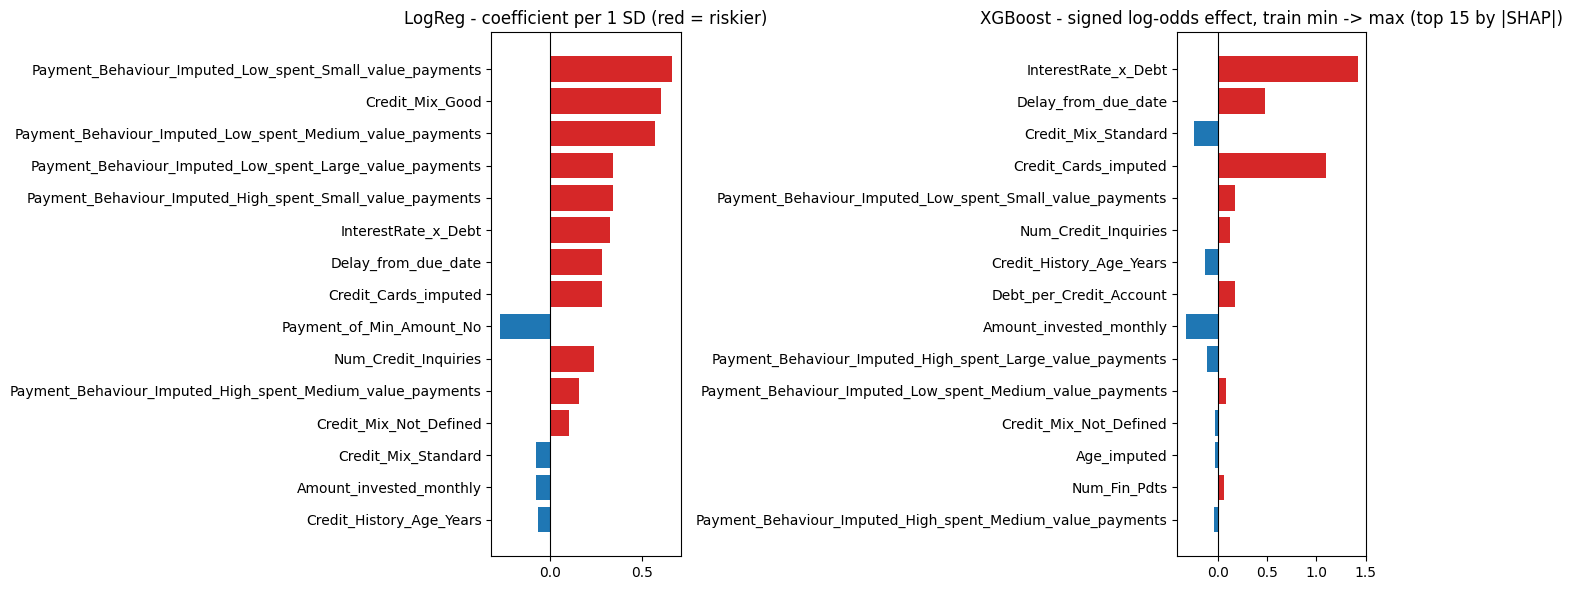

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
t = lr_coef.head(15).iloc[::-1]
axes[0].barh(t.feature, t.coef_per_1sd, color=np.where(t.coef_per_1sd > 0, "tab:red", "tab:blue"))
axes[0].axvline(0, c="k", lw=0.8); axes[0].set_title("LogReg - coefficient per 1 SD (red = riskier)")
t = shap_imp.head(15).iloc[::-1]
axes[1].barh(t.index, t.ice_effect_min_to_max, color=np.where(t.constraint > 0, "tab:red", "tab:blue"))
axes[1].axvline(0, c="k", lw=0.8)
axes[1].set_title("XGBoost - signed log-odds effect, train min -> max (top 15 by |SHAP|)")
plt.tight_layout(); plt.show()

In [40]:
# must match the arguments passed to process_features_gold_table_main above
model_train_date_str = "2025-06-01"

config = {}
config["model_train_date_str"] = model_train_date_str
config["data_start_date_str"] = data_start_date_str
config["validation_period_months"] = 1
config["test_period_months"] = 2
config["oot_period_months"] = 2
config["label_definition"] = "30dpd_6mob"
config["model_train_date"] = datetime.strptime(model_train_date_str, "%Y-%m-%d")
config["oot_end_date"] = config["model_train_date"] - timedelta(days=1)
config["oot_start_date"] = config["model_train_date"] - relativedelta(months=config["oot_period_months"])
config["test_end_date"] = config["oot_start_date"] - timedelta(days=1)
config["test_start_date"] = config["test_end_date"] - relativedelta(months=config["test_period_months"]) + timedelta(days=1)
config["validation_end_date"] = config["test_start_date"] - timedelta(days=1)
config["validation_start_date"] = config["validation_end_date"] - relativedelta(months=config["validation_period_months"]) + timedelta(days=1)
config["train_start_date"] = datetime.strptime(data_start_date_str, "%Y-%m-%d")
config["train_end_date"] = config["validation_start_date"] - timedelta(days=1)

# every row's label date must sit inside its split window
for s in SPLITS:
    lo, hi = config[f"{s}_start_date"], config[f"{s}_end_date"]
    d = df.loc[df.data_split == s, "labels_snapshot_date"]
    assert d.between(lo, hi).all(), f"{s}: label dates outside {lo.date()}..{hi.date()}"
    print(f"{s:<10} {lo.date()} -> {hi.date()}  rows={len(d):>5}  actual {d.min().date()} -> {d.max().date()}")

train      2023-01-01 -> 2024-12-31  rows= 8974  actual 2023-07-01 -> 2024-12-01
validation 2025-01-01 -> 2025-01-31  rows=  505  actual 2025-01-01 -> 2025-01-01
test       2025-02-01 -> 2025-03-31  rows= 1036  actual 2025-02-01 -> 2025-03-01
oot        2025-04-01 -> 2025-05-31  rows=  944  actual 2025-04-01 -> 2025-05-01


In [42]:
INVALID_VALUE_RULES_SPEC = {
    "Interest_Rate":           (">", 50),
    "Num_Credit_Inquiries":    (">", 30),
    "Num_of_Delayed_Payment":  (">", 50),
    "Monthly_Balance":         ("abs>", 1e9),
    "Amount_invested_monthly": ("==", 10000),
}
_OPS = {">": lambda s, v: s > v, "abs>": lambda s, v: s.abs() > v, "==": lambda s, v: s == v}

# check the spec flags exactly the same rows as the lambdas basic_clean actually used
assert set(INVALID_VALUE_RULES_SPEC) == set(INVALID_VALUE_RULES)
for c, (op, v) in INVALID_VALUE_RULES_SPEC.items():
    s = combined[c].astype(float)
    assert INVALID_VALUE_RULES[c](s).equals(_OPS[op](s, v)), f"spec differs from lambda for {c}"
    print(f"  {c:<25} {op:>4} {v:<12} {int(_OPS[op](s, v).sum()):>5} rows (identical to lambda)")

CLEANING_CONFIG = {"non_negative_cols": NON_NEGATIVE_COLS,
                   "invalid_value_rules": INVALID_VALUE_RULES_SPEC,
                   "redundant_cols": REDUNDANT_COLS}

  Interest_Rate                > 50             251 rows (identical to lambda)
  Num_Credit_Inquiries         > 30             174 rows (identical to lambda)
  Num_of_Delayed_Payment       > 50              96 rows (identical to lambda)
  Monthly_Balance           abs> 1000000000.0     1 rows (identical to lambda)
  Amount_invested_monthly     == 10000          519 rows (identical to lambda)


In [43]:
def to_py(d):
    # numpy scalars -> plain python, so the artefact prints / serialises cleanly
    return {k: (v.item() if isinstance(v, np.generic) else v) for k, v in d.items()}


def build_model_artefact(algo, metric_name, pipeline, features, hp_params, extra):
    pre, clf = pipeline.named_steps["pre"], pipeline.named_steps["model"]
    num_step = pre.named_transformers_["num"]
    m = metrics[metrics.model == metric_name].set_index("split")

    model_artefact = {}
    model_artefact["model"] = clf
    model_artefact["model_version"] = f"credit_model_{algo}_" + config["model_train_date_str"].replace("-", "_")
    model_artefact["preprocessing_transformers"] = {}
    model_artefact["preprocessing_transformers"]["preprocessor"] = pre
    model_artefact["preprocessing_transformers"]["stdscaler"] = (
        num_step.named_steps["scale"] if isinstance(num_step, Pipeline) else None)      # XGB: no scaling
    model_artefact["preprocessing_transformers"]["quantile_capper"] = (
        num_step.named_steps["cap"] if isinstance(num_step, Pipeline) else num_step)
    model_artefact["data_dates"] = config
    model_artefact["data_stats"] = {}
    for s in SPLITS:
        model_artefact["data_stats"][f"X_{s}"] = int((df.data_split == s).sum())
    for s in SPLITS:
        model_artefact["data_stats"][f"y_{s}"] = round(float(df.loc[df.data_split == s, TARGET].mean()), 2)
    model_artefact["results"] = {}
    for s in SPLITS:
        model_artefact["results"][f"auc_{s}"] = float(m.loc[s, "AUC"])
    for s in SPLITS:
        model_artefact["results"][f"gini_{s}"] = round(2 * float(m.loc[s, "AUC"]) - 1, 3)
    for s in SPLITS:
        model_artefact["results"][f"ks_{s}"] = round(float(m.loc[s, "KS"]), 3)
    model_artefact["hp_params"] = to_py(hp_params)
    model_artefact["features"] = {"raw_input_features": list(features),
                                  "model_input_columns": list(pre.get_feature_names_out())}
    model_artefact["decision_threshold"] = float(thresholds[metric_name])
    model_artefact["feature_cleaning"] = {**CLEANING_CONFIG,
                                          "note": "utils.model_preprocessing.basic_clean(df, **cfg) before preprocessor"}
    model_artefact.update(extra)
    return model_artefact


lr_artefact = build_model_artefact(
    "logreg", "LogReg", lr_model, lr_features,
    hp_params={k.replace("model__", ""): v for k, v in lr_search.best_params_.items()},
    extra={"coefficients": lr_coef, "lr_dropped_for_sign": dropped_for_sign})

xgb_artefact = build_model_artefact(
    "xgb", "XGBoost", xgb_model, xgb_features,
    hp_params={**best, "n_estimators": int(xgb_clf.best_iteration + 1),
               "n_estimators_selected_by": "early stopping on validation"},
    extra={"monotone_constraints": xgb_monotone, "direction_table": dir_tbl,
           "monotonicity_check": mono_check, "shap_importance": shap_imp})

artefacts = [lr_artefact, xgb_artefact]
for a in artefacts:
    print("=" * 30, a["model_version"], "=" * 30)
    pprint.pprint({k: v for k, v in a.items() if not isinstance(v, pd.DataFrame)}, width=110, compact=True)

champion = max(artefacts, key=lambda a: a["results"]["gini_test"])
print("\nchampion on TEST Gini (OOT is report-only):", champion["model_version"])

============================== credit_model_logreg_2025_06_01 ==============================
{'data_dates': {'data_start_date_str': '2023-01-01',
                'label_definition': '30dpd_6mob',
                'model_train_date': datetime.datetime(2025, 6, 1, 0, 0),
                'model_train_date_str': '2025-06-01',
                'oot_end_date': datetime.datetime(2025, 5, 31, 0, 0),
                'oot_period_months': 2,
                'oot_start_date': datetime.datetime(2025, 4, 1, 0, 0),
                'test_end_date': datetime.datetime(2025, 3, 31, 0, 0),
                'test_period_months': 2,
                'test_start_date': datetime.datetime(2025, 2, 1, 0, 0),
                'train_end_date': datetime.datetime(2024, 12, 31, 0, 0),
                'train_start_date': datetime.datetime(2023, 1, 1, 0, 0),
                'validation_end_date': datetime.datetime(2025, 1, 31, 0, 0),
                'validation_period_months': 1,
                'validation_start_date': d

## Save model artefacts

In [44]:
model_bank_directory = "model_bank/"
os.makedirs(model_bank_directory, exist_ok=True)

for a in artefacts:
    file_path = os.path.join(model_bank_directory, a["model_version"] + ".pkl")
    with open(file_path, "wb") as file:
        pickle.dump(a, file)
    print(f"Model saved to {file_path}")

# human-readable companions
report.to_csv(os.path.join(model_bank_directory, "feature_selection_report.csv"))
metrics.to_csv(os.path.join(model_bank_directory, "metrics_by_split.csv"), index=False)

Model saved to model_bank/credit_model_logreg_2025_06_01.pkl
Model saved to model_bank/credit_model_xgb_2025_06_01.pkl


## Test load pickle and make model inference
Reloads each `.pkl` and scores OOT through the stored preprocessor and model. The AUC must equal the stored
`results['auc_oot']`, which proves the artefact is self-contained.

In [45]:
for a in artefacts:
    file_path = os.path.join(model_bank_directory, a["model_version"] + ".pkl")
    with open(file_path, "rb") as file:
        loaded_model_artefact = pickle.load(file)

    feats = loaded_model_artefact["features"]["raw_input_features"]
    X_oot, y_oot = split_xy("oot", feats)                      # df is already basic_clean-ed
    X_oot_processed = loaded_model_artefact["preprocessing_transformers"]["preprocessor"].transform(X_oot)
    y_pred_proba = loaded_model_artefact["model"].predict_proba(X_oot_processed)[:, 1]
    oot_auc_score = roc_auc_score(y_oot, y_pred_proba)

    assert np.isclose(oot_auc_score, loaded_model_artefact["results"]["auc_oot"])
    print(f"{loaded_model_artefact['model_version']}: OOT AUC = {oot_auc_score:.4f} "
          f"(matches stored) | Gini = {2 * oot_auc_score - 1:.3f}")
print("Models loaded successfully!")

credit_model_logreg_2025_06_01: OOT AUC = 0.7609 (matches stored) | Gini = 0.522
credit_model_xgb_2025_06_01: OOT AUC = 0.7861 (matches stored) | Gini = 0.572
Models loaded successfully!


## BackFill

In [46]:
import contextlib, io

# set up config
backfill_config = {
    "start_date_str": "2023-01-01",
    "end_date_str": "2024-12-01",
    "feature_store_path": "datamart/gold/feature_store/gold_feature_store_main_cs.parquet",
    "model_bank_directory": "model_bank/",
    "predictions_root": "datamart/gold/model_predictions/",
    "scoring_date_col": "financials_snapshot_date",
}
model_names = [a["model_version"] + ".pkl" for a in artefacts]      # LR and XGB

dates_str_lst = generate_first_of_month_dates(backfill_config["start_date_str"], backfill_config["end_date_str"])
pprint.pprint(backfill_config)
print(model_names)
print(dates_str_lst)

{'end_date_str': '2024-12-01',
 'feature_store_path': 'datamart/gold/feature_store/gold_feature_store_main_cs.parquet',
 'model_bank_directory': 'model_bank/',
 'predictions_root': 'datamart/gold/model_predictions/',
 'scoring_date_col': 'financials_snapshot_date',
 'start_date_str': '2023-01-01'}
['credit_model_logreg_2025_06_01.pkl', 'credit_model_xgb_2025_06_01.pkl']
['2023-01-01', '2023-02-01', '2023-03-01', '2023-04-01', '2023-05-01', '2023-06-01', '2023-07-01', '2023-08-01', '2023-09-01', '2023-10-01', '2023-11-01', '2023-12-01', '2024-01-01', '2024-02-01', '2024-03-01', '2024-04-01', '2024-05-01', '2024-06-01', '2024-07-01', '2024-08-01', '2024-09-01', '2024-10-01', '2024-11-01', '2024-12-01']


In [47]:
def model_inference(snapshot_date_str, model_name, spark, cfg=backfill_config):
    # --- load model artefact from model bank ---
    model_artefact_filepath = os.path.join(cfg["model_bank_directory"], model_name)
    with open(model_artefact_filepath, "rb") as file:
        model_artefact = pickle.load(file)

    # --- load feature store rows observed on this snapshot date ---
    features_sdf = (spark.read.parquet(cfg["feature_store_path"])
                    .filter(F.col(cfg["scoring_date_col"]) == F.to_date(F.lit(snapshot_date_str))))
    n_rows = features_sdf.count()
    if n_rows == 0:
        print(f"{model_name} {snapshot_date_str}: no rows in feature store - skipped")
        return None
    features_pdf = features_sdf.toPandas()

    # --- preprocess: same basic_clean as training (its printout silenced) + stored preprocessor ---
    with contextlib.redirect_stdout(io.StringIO()):
        clean_pdf = basic_clean(features_pdf)
    X_inference = clean_pdf[model_artefact["features"]["raw_input_features"]]
    X_inference = model_artefact["preprocessing_transformers"]["preprocessor"].transform(X_inference)

    # --- model prediction inference ---
    y_inference = model_artefact["model"].predict_proba(X_inference)[:, 1]

    y_inference_pdf = clean_pdf[["Customer_ID", "loan_id"]].copy()
    y_inference_pdf["snapshot_date"] = datetime.strptime(snapshot_date_str, "%Y-%m-%d").date()
    y_inference_pdf["model_name"] = model_name
    y_inference_pdf["model_predictions"] = y_inference.astype(float)
    y_inference_pdf["decision_threshold"] = float(model_artefact["decision_threshold"])
    y_inference_pdf["predicted_default"] = (y_inference >= model_artefact["decision_threshold"]).astype(int)

    # --- save model inference to datamart gold table ---
    gold_directory = os.path.join(cfg["predictions_root"], model_name[:-4]) + "/"
    os.makedirs(gold_directory, exist_ok=True)
    partition_name = model_name[:-4] + "_predictions_" + snapshot_date_str.replace("-", "_") + ".parquet"
    filepath = gold_directory + partition_name
    spark.createDataFrame(y_inference_pdf).write.mode("overwrite").parquet(filepath)
    print(f"{model_name} {snapshot_date_str}: {n_rows:>5} rows -> {filepath}")
    return y_inference_pdf

In [48]:
for model_name in model_names:
    for snapshot_date in dates_str_lst:
        model_inference(snapshot_date, model_name, spark)

credit_model_logreg_2025_06_01.pkl 2023-01-01:   530 rows -> datamart/gold/model_predictions/credit_model_logreg_2025_06_01/credit_model_logreg_2025_06_01_predictions_2023_01_01.parquet


credit_model_logreg_2025_06_01.pkl 2023-02-01:   501 rows -> datamart/gold/model_predictions/credit_model_logreg_2025_06_01/credit_model_logreg_2025_06_01_predictions_2023_02_01.parquet


credit_model_logreg_2025_06_01.pkl 2023-03-01:   506 rows -> datamart/gold/model_predictions/credit_model_logreg_2025_06_01/credit_model_logreg_2025_06_01_predictions_2023_03_01.parquet


credit_model_logreg_2025_06_01.pkl 2023-04-01:   510 rows -> datamart/gold/model_predictions/credit_model_logreg_2025_06_01/credit_model_logreg_2025_06_01_predictions_2023_04_01.parquet


credit_model_logreg_2025_06_01.pkl 2023-05-01:   521 rows -> datamart/gold/model_predictions/credit_model_logreg_2025_06_01/credit_model_logreg_2025_06_01_predictions_2023_05_01.parquet


credit_model_logreg_2025_06_01.pkl 2023-06-01:   517 rows -> datamart/gold/model_predictions/credit_model_logreg_2025_06_01/credit_model_logreg_2025_06_01_predictions_2023_06_01.parquet


... (36 outputs left out)

credit_model_xgb_2025_06_01.pkl 2024-08-01:   543 rows -> datamart/gold/model_predictions/credit_model_xgb_2025_06_01/credit_model_xgb_2025_06_01_predictions_2024_08_01.parquet


credit_model_xgb_2025_06_01.pkl 2024-09-01:   493 rows -> datamart/gold/model_predictions/credit_model_xgb_2025_06_01/credit_model_xgb_2025_06_01_predictions_2024_09_01.parquet


credit_model_xgb_2025_06_01.pkl 2024-10-01:   456 rows -> datamart/gold/model_predictions/credit_model_xgb_2025_06_01/credit_model_xgb_2025_06_01_predictions_2024_10_01.parquet


credit_model_xgb_2025_06_01.pkl 2024-11-01:   488 rows -> datamart/gold/model_predictions/credit_model_xgb_2025_06_01/credit_model_xgb_2025_06_01_predictions_2024_11_01.parquet
credit_model_xgb_2025_06_01.pkl 2024-12-01: no rows in feature store - skipped


In [49]:
backfill_check = []
for model_name in model_names:
    folder_path = os.path.join(backfill_config["predictions_root"], model_name[:-4]) + "/"
    files_list = [folder_path + os.path.basename(f) for f in glob.glob(os.path.join(folder_path, '*'))]
    preds_sdf = spark.read.option("header", "true").parquet(*files_list)
    print(model_name, "row_count:", preds_sdf.count())
    preds_sdf.show(5)

    preds = preds_sdf.toPandas()
    assert preds.loan_id.is_unique, "duplicate loan predictions"
    chk = preds.merge(df[["loan_id", "data_split", TARGET]], on="loan_id", how="inner", validate="one_to_one")
    for s in SPLITS:
        d = chk[chk.data_split == s]
        backfill_check.append({"model": model_name[:-4], "split": s, "rows": len(d),
                               "AUC_backfill": roc_auc_score(d[TARGET], d.model_predictions)})

backfill_check = pd.DataFrame(backfill_check)
expected = {(a["model_version"], s): a["results"][f"auc_{s}"] for a in artefacts for s in SPLITS}
backfill_check["AUC_notebook"] = [expected[(m, s)] for m, s in zip(backfill_check.model, backfill_check.split)]
backfill_check["match"] = np.isclose(backfill_check.AUC_backfill, backfill_check.AUC_notebook)
assert backfill_check.match.all(), "backfill scores differ from notebook scores"
backfill_check.round(4)

credit_model_logreg_2025_06_01.pkl row_count: 11459
+-----------+--------------------+-------------+--------------------+-------------------+-------------------+-----------------+
|Customer_ID|             loan_id|snapshot_date|          model_name|  model_predictions| decision_threshold|predicted_default|
+-----------+--------------------+-------------+--------------------+-------------------+-------------------+-----------------+
| CUS_0xad5e|CUS_0xad5e_2024_0...|   2024-02-01|credit_model_logr...| 0.6470471193678105|0.47940305142529904|                1|
|  CUS_0xec4|CUS_0xec4_2024_02_01|   2024-02-01|credit_model_logr...|0.38470258845450594|0.47940305142529904|                0|
| CUS_0x5ba4|CUS_0x5ba4_2024_0...|   2024-02-01|credit_model_logr...|  0.212983864433699|0.47940305142529904|                0|
| CUS_0x86b5|CUS_0x86b5_2024_0...|   2024-02-01|credit_model_logr...| 0.8216911399877411|0.47940305142529904|                1|
| CUS_0x9535|CUS_0x9535_2024_0...|   2024-02-01|cred

credit_model_xgb_2025_06_01.pkl row_count: 11459
+-----------+--------------------+-------------+--------------------+-------------------+------------------+-----------------+
|Customer_ID|             loan_id|snapshot_date|          model_name|  model_predictions|decision_threshold|predicted_default|
+-----------+--------------------+-------------+--------------------+-------------------+------------------+-----------------+
| CUS_0xad5e|CUS_0xad5e_2024_0...|   2024-02-01|credit_model_xgb_...| 0.3843315541744232|0.2282814234495163|                1|
|  CUS_0xec4|CUS_0xec4_2024_02_01|   2024-02-01|credit_model_xgb_...| 0.1492193639278412|0.2282814234495163|                0|
| CUS_0x5ba4|CUS_0x5ba4_2024_0...|   2024-02-01|credit_model_xgb_...|0.10936063528060913|0.2282814234495163|                0|
| CUS_0x86b5|CUS_0x86b5_2024_0...|   2024-02-01|credit_model_xgb_...| 0.6299130916595459|0.2282814234495163|                1|
| CUS_0x9535|CUS_0x9535_2024_0...|   2024-02-01|credit_model_x

,model,split,rows,AUC_backfill,AUC_notebook,match
0,credit_model_logreg_2025_06_01,train,8974,0.7611,0.7611,True
1,credit_model_logreg_2025_06_01,validation,505,0.7362,0.7362,True
2,credit_model_logreg_2025_06_01,test,1036,0.7587,0.7587,True
3,credit_model_logreg_2025_06_01,oot,944,0.7609,0.7609,True
4,credit_model_xgb_2025_06_01,train,8974,0.7972,0.7972,True
5,credit_model_xgb_2025_06_01,validation,505,0.7877,0.7877,True
6,credit_model_xgb_2025_06_01,test,1036,0.7788,0.7788,True
7,credit_model_xgb_2025_06_01,oot,944,0.7861,0.7861,True
